# One-shot instance segmentation - Phase 1

Frozen `facebook/dinov2-base` features locate the reference object in the target
image, and a frozen `facebook/sam-vit-base` refines that location into a mask.
Nothing is trained and no other repository is used: the modules below are
embedded copies of this project.

| stage | module | output |
| --- | --- | --- |
| 1. features | `models/feature_encoder.py` | patch-token grid for both images |
| 2. reference | `matching/reference_representation.py` | masked reference tokens |
| 3-4. correspondence | `matching/correspondence.py` | `similarity_map` |
| 5. localization | `matching/localization.py` | `candidate_region`, boxes, confidence |
| 6. segmentation | `models/segmenter.py` | `predicted_mask` |
| 7-9. pipeline, metrics, plots | `pipeline/`, `evaluation/`, `visualization/` | result, IoU/Dice/P/R, figures |

Generated from source commit content, fingerprint `00d1aa0f1892abf7`. Re-run
`python tools/embed_sources.py` in VS Code after changing the modules.

## 1. Environment

In [55]:
!pip -q install "transformers>=4.40" accelerate safetensors 2>/dev/null || pip -q install "transformers>=4.40" accelerate safetensors

import importlib
import subprocess
import sys

for package in ("torch", "transformers", "numpy", "scipy", "matplotlib", "PIL"):
    try:
        module = importlib.import_module(package)
        print(f"{package:14s} {getattr(module, '__version__', 'ok')}")
    except ImportError:
        print(f"{package:14s} MISSING - install it before continuing")

try:
    import torch

    print("cuda available:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
except Exception as error:
    print("torch check failed:", error)

torch          2.11.0+cu130
transformers   5.17.0
numpy          2.1.3
scipy          1.16.3
matplotlib     3.10.0
PIL            11.3.0
cuda available: True Tesla T4


## Project source

`# Generated by tools/embed_sources.py - do not edit this file directly.`

In [56]:
import os
import sys

BUNDLE_ROOT = "one_shot_src"
EXPECTED_SOURCE_REVISION = "00d1aa0f1892abf7"
SOURCE_FILES = {
    "evaluation/cases.py": "\"\"\"Evaluation cases: the bridge between a dataset on disk and the pipeline.\n\nA few-shot case is a reference image plus its mask, a target image, and\noptionally a target mask to score against. This module stays deliberately\nformat-agnostic: it does not know how COCO-20i, FSS-1000, LVIS-92i, PACO-Part or\nPascal-Part encode their splits, because those come from external archives whose\ninternal layout is not ours to assume. Instead, a case is described by paths, and\n`cases_from_manifest` reads that description from JSON:\n\n    {\n      \"root\": \"datasets\",\n      \"cases\": [\n        {\"name\": \"coco-20i-val-0001\",\n         \"reference_image\": \"COCO2014/val2014/COCO_val2014_000000391895.jpg\",\n         \"reference_mask\":  \"COCO2014/annotations/val2014/000000391895.png\",\n         \"target_image\":    \"COCO2014/val2014/COCO_val2014_000000000139.jpg\",\n         \"target_mask\":     \"COCO2014/annotations/val2014/000000000139.png\"}\n      ]\n    }\n\nMultiple instances in one mask file are supported through `instance_index`, which\nkeeps only the requested label, so a converted COCO-20i mask file and a\nsingle-object Pascal-Part mask both work unchanged.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport json\nimport os\nfrom dataclasses import dataclass, field\nfrom typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple\n\nimport numpy as np\n\nfrom evaluation.metrics import EvaluationReport, evaluate_results\nfrom matching.reference_representation import MaskInput\nfrom models.feature_encoder import ImageInput, to_pil_image\n\n\n@dataclass\nclass Case:\n    \"\"\"One few-shot example.\n\n    Attributes:\n        name: identifier used in the report table.\n        reference_image: image containing the query object.\n        reference_mask: binary mask of that object.\n        target_image: image to segment.\n        target_mask: optional ground truth for scoring.\n        meta: anything else worth keeping (category, dataset, split).\n    \"\"\"\n\n    name: str\n    reference_image: ImageInput\n    reference_mask: MaskInput\n    target_image: ImageInput\n    target_mask: Optional[MaskInput] = None\n    meta: Dict[str, Any] = field(default_factory=dict)\n\n    @property\n    def scorable(self) -> bool:\n        return self.target_mask is not None\n\n    def describe(self) -> Dict[str, Any]:\n        return {\"name\": self.name, \"scorable\": self.scorable, **self.meta}\n\n\ndef load_mask(path: str, instance_index: Optional[int] = None) -> np.ndarray:\n    \"\"\"Read a mask image; `instance_index` keeps only that instance's label.\n\n    White foreground over black background is assumed. A multi-colour palette\n    file is handled by treating the top-left pixel as the background and every\n    distinct remaining colour as one instance.\n    \"\"\"\n    from PIL import Image\n\n    array = np.asarray(Image.open(path))\n    if array.ndim == 3:\n        background = array[0, 0].astype(np.int16)\n        mask = np.abs(array.astype(np.int16) - background).sum(axis=-1) > 24\n        if instance_index is not None:\n            colours = np.unique(array[mask]) if mask.any() else np.zeros((0, array.shape[-1]), array.dtype)\n            if instance_index >= len(colours):\n                raise IndexError(\n                    f\"{path} holds {len(colours)} instance labels, cannot take index {instance_index}\"\n                )\n            mask = (array == colours[instance_index]).all(axis=-1)\n    else:\n        if instance_index is not None:\n            raise ValueError(f\"{path} is a single-instance grayscale mask; drop instance_index\")\n        mask = array > 127\n    return mask.astype(bool)\n\n\ndef case_from_paths(\n    root: str,\n    name: str,\n    reference_image: str,\n    reference_mask: str,\n    target_image: str,\n    target_mask: Optional[str] = None,\n    instance_index: Optional[int] = None,\n    target_instance_index: Optional[int] = None,\n    meta: Optional[Dict[str, Any]] = None,\n) -> Case:\n    \"\"\"Build a `Case` from paths relative to `root`.\"\"\"\n    def resolve(relative: Optional[str]) -> Optional[str]:\n        if relative is None:\n            return None\n        path = relative if os.path.isabs(relative) else os.path.join(root, relative)\n        if not os.path.exists(path):\n            raise FileNotFoundError(path)\n        return path\n\n    reference_path = resolve(reference_image)\n    target_path = resolve(target_image)\n    assert reference_path is not None and target_path is not None\n    return Case(\n        name=name,\n        reference_image=to_pil_image(reference_path),\n        reference_mask=load_mask(resolve(reference_mask) or \"\", instance_index),\n        target_image=to_pil_image(target_path),\n        target_mask=None if target_mask is None else load_mask(resolve(target_mask) or \"\", target_instance_index),\n        meta=dict(meta or {}),\n    )\n\n\ndef cases_from_manifest(path: str, root: Optional[str] = None) -> List[Case]:\n    \"\"\"Read a JSON manifest describing several cases.\"\"\"\n    with open(path, \"r\", encoding=\"utf-8\") as handle:\n        manifest = json.load(handle)\n    base = root or manifest.get(\"root\") or os.path.dirname(os.path.abspath(path))\n    cases: List[Case] = []\n    for entry in manifest.get(\"cases\", []):\n        meta = {key: value for key, value in entry.items() if key not in {\n            \"name\", \"reference_image\", \"reference_mask\", \"target_image\", \"target_mask\",\n            \"instance_index\", \"target_instance_index\"}}\n        cases.append(\n            case_from_paths(\n                base,\n                entry[\"name\"],\n                entry[\"reference_image\"],\n                entry[\"reference_mask\"],\n                entry[\"target_image\"],\n                entry.get(\"target_mask\"),\n                entry.get(\"instance_index\"),\n                entry.get(\"target_instance_index\"),\n                meta,\n            )\n        )\n    return cases\n\n\ndef run_cases(pipeline: Any, cases: Sequence[Case], verbose: bool = True) -> EvaluationReport:\n    \"\"\"Run every case through the pipeline and score the ones with a ground truth.\"\"\"\n    from evaluation.metrics import evaluate_mask\n\n    rows: List[Tuple[str, Optional[np.ndarray], Optional[np.ndarray], Any]] = []\n    for case in cases:\n        result = pipeline.segment_object(case.reference_image, case.reference_mask, case.target_image)\n        rows.append((case.name, result.predicted_mask, case.target_mask, result))\n        if verbose:\n            suffix = \"\" if not case.scorable else f\" IoU {evaluate_mask(result.predicted_mask, case.target_mask).iou:.3f}\"\n            print(f\"{case.name:32s} conf {result.confidence:.3f} \"\n                  f\"{result.runtime['total']:.2f}s{suffix}\")\n    scorable = [row for row in rows if row[2] is not None]\n    if not scorable:\n        return EvaluationReport(\n            rows=[{\"example\": name, \"confidence\": float(result.confidence),\n                   \"seconds\": float(result.runtime[\"total\"])}\n                  for name, _, _, result in rows],\n            metric_names=(\"confidence\",),\n        )\n    return evaluate_results(scorable)\n",
    "evaluation/metrics.py": "\"\"\"Step 9 - evaluation metrics for a small, verified set of examples.\n\nThe four metrics requested for Phase 1 are IoU, Dice, precision and recall.\nThey are computed from boolean masks, tolerate empty inputs by returning\ndefined values (1.0 when both sides are empty, 0.0 when only the prediction is\nempty), and are paired with a `summarise` helper that reports the mean plus the\nper-example rows, so a handful of results stays readable.\n\nPhase 1 evaluates a handful of manually checked examples, so this module\ndeliberately has no dataset iteration, no sweeps and no aggregation tricks.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nfrom dataclasses import dataclass\nfrom typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple\n\nimport numpy as np\n\nfrom matching.reference_representation import MaskInput, to_binary_mask\n\nEPSILON = 1e-7\n\n\n@dataclass\nclass MaskMetrics:\n    \"\"\"Overlap metrics for one prediction against one ground-truth mask.\"\"\"\n\n    iou: float\n    dice: float\n    precision: float\n    recall: float\n    true_positive: int\n    false_positive: int\n    false_negative: int\n\n    def to_dict(self) -> Dict[str, float]:\n        return {\n            \"iou\": self.iou,\n            \"dice\": self.dice,\n            \"precision\": self.precision,\n            \"recall\": self.recall,\n            \"true_positive\": float(self.true_positive),\n            \"false_positive\": float(self.false_positive),\n            \"false_negative\": float(self.false_negative),\n        }\n\n    def __str__(self) -> str:\n        return f\"IoU {self.iou:.3f} | Dice {self.dice:.3f} | P {self.precision:.3f} | R {self.recall:.3f}\"\n\n\ndef _as_bool(mask: Optional[MaskInput]) -> np.ndarray:\n    if mask is None:\n        return np.zeros((0, 0), dtype=bool)\n    tensor = to_binary_mask(mask)\n    return (tensor.squeeze() > 0.5).cpu().numpy().astype(bool)\n\n\ndef evaluate_mask(prediction: Optional[MaskInput], ground_truth: MaskInput) -> MaskMetrics:\n    \"\"\"IoU, Dice, precision and recall for one predicted mask.\"\"\"\n    predicted = _as_bool(prediction)\n    truth = _as_bool(ground_truth)\n\n    if predicted.shape != truth.shape:\n        if predicted.size == 0:\n            predicted = np.zeros(truth.shape, dtype=bool)\n        else:\n            import torch.nn.functional as F\n\n            resized = F.interpolate(\n                to_binary_mask(prediction), size=truth.shape[-2:], mode=\"nearest\"\n            )\n            predicted = (resized.squeeze() > 0.5).cpu().numpy().astype(bool)\n\n    intersection = int(np.logical_and(predicted, truth).sum())\n    predicted_area = int(predicted.sum())\n    truth_area = int(truth.sum())\n    union = predicted_area + truth_area - intersection\n\n    if union == 0:\n        iou = 1.0\n        dice = 1.0\n    else:\n        iou = intersection / union\n        dice = (2.0 * intersection) / (predicted_area + truth_area) if (predicted_area + truth_area) else 0.0\n\n    precision = intersection / predicted_area if predicted_area else (1.0 if truth_area == 0 else 0.0)\n    recall = intersection / truth_area if truth_area else (1.0 if predicted_area == 0 else 0.0)\n\n    return MaskMetrics(\n        iou=float(iou),\n        dice=float(dice),\n        precision=float(precision),\n        recall=float(recall),\n        true_positive=intersection,\n        false_positive=predicted_area - intersection,\n        false_negative=truth_area - intersection,\n    )\n\n\n@dataclass\nclass EvaluationReport:\n    \"\"\"Per-example rows plus the mean of each metric.\n\n    Attributes:\n        rows: one dict per example, containing the metrics, the confidence and\n            the runtime when available.\n        metric_names: the metrics that the mean is computed over.\n    \"\"\"\n\n    rows: List[Dict[str, Any]]\n    metric_names: Tuple[str, ...] = (\"iou\", \"dice\", \"precision\", \"recall\")\n\n    def mean(self, metric: str = \"iou\") -> float:\n        values = [float(row[metric]) for row in self.rows if metric in row]\n        return float(np.mean(values)) if values else float(\"nan\")\n\n    def summary(self) -> Dict[str, float]:\n        return {name: self.mean(name) for name in self.metric_names}\n\n    def to_table(self) -> str:\n        if not self.rows:\n            return \"no evaluated examples\"\n        header = f\"{'example':<24}{'IoU':>8}{'Dice':>8}{'P':>8}{'R':>8}{'conf':>8}{'sec':>8}\"\n        lines = [header, \"-\" * len(header)]\n        for row in self.rows:\n            lines.append(\n                f\"{str(row.get('example', '')):<24}\"\n                f\"{row.get('iou', float('nan')):>8.3f}\"\n                f\"{row.get('dice', float('nan')):>8.3f}\"\n                f\"{row.get('precision', float('nan')):>8.3f}\"\n                f\"{row.get('recall', float('nan')):>8.3f}\"\n                f\"{row.get('confidence', float('nan')):>8.3f}\"\n                f\"{row.get('seconds', float('nan')):>8.2f}\"\n            )\n        lines.append(\"-\" * len(header))\n        summary = self.summary()\n        lines.append(\n            f\"{'mean':<24}\" + \"\".join(f\"{summary[name]:>8.3f}\" for name in self.metric_names)\n        )\n        return \"\\n\".join(lines)\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\"rows\": self.rows, \"summary\": self.summary(), \"num_examples\": len(self.rows)}\n\n\ndef evaluate_results(\n    examples: Sequence[Tuple[str, Optional[MaskInput], MaskInput, Any]],\n) -> EvaluationReport:\n    \"\"\"Score `(name, prediction, ground_truth, result)` tuples into a report.\n\n    The fourth element is the `OneShotResult` the prediction came from, used only\n    to attach the confidence and the runtime; `None` is accepted.\n    \"\"\"\n    rows: List[Dict[str, Any]] = []\n    for name, prediction, ground_truth, result in examples:\n        metrics = evaluate_mask(prediction, ground_truth)\n        row: Dict[str, Any] = {\"example\": name, **metrics.to_dict()}\n        if result is not None:\n            row[\"confidence\"] = float(getattr(result, \"confidence\", float(\"nan\")))\n            row[\"seconds\"] = float(getattr(result, \"runtime\", {}).get(\"total\", float(\"nan\")))\n        rows.append(row)\n    return EvaluationReport(rows=rows)\n",
    "matching/correspondence.py": "\"\"\"Steps 3 and 4 - target representation and feature correspondence.\n\nStep 3 wraps the target image features in a `TargetRepresentation`: every patch\nof the target keeps its features and its grid position, so a patch-level\ncomparison is a plain matrix product.\n\nStep 4 turns that into a *correspondence field*. For each target patch we\nmeasure how similar it is to the reference object and resample the result to\npixel resolution, producing the `similarity_map` the later stages consume.\n\nTwo aggregations are available:\n\n* `max` - the single best-matching reference patch per target patch. Sharp and\n  good for texture repetition, but sensitive to a few spuriously high scores.\n* `prototype` - similarity to the coverage-weighted mean reference token. More\n  robust, blurrier, and it describes the object as a whole rather than by its\n  most distinctive patch.\n\n`both` returns the two maps separately plus their average, which is the default\nin the pipeline: agreement between the two is a cheap, honest confidence signal.\n\nSimilarity is computed on L2-normalised tokens, so the cosine similarity is a\ndot product. Patch scores are finally min-max normalised using robust percentile\nclips, which keeps a handful of extreme values from flattening the rest of the\nmap.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport warnings\nfrom dataclasses import dataclass\nfrom typing import Any, Dict, Optional, Tuple, Union\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\n\nfrom models.feature_encoder import FeatureMap\nfrom matching.reference_representation import ReferenceRepresentation\n\nAGGREGATIONS = (\"max\", \"prototype\", \"both\")\n\n\n@dataclass\nclass TargetRepresentation:\n    \"\"\"Features of the target image, flattened for patch-wise comparison.\n\n    Attributes:\n        tokens: (M, C) L2-normalised target patch tokens, row-major over the grid.\n        features: the underlying `FeatureMap`, kept for visualisation.\n    \"\"\"\n\n    tokens: torch.Tensor\n    features: FeatureMap\n\n    @property\n    def grid_size(self) -> Tuple[int, int]:\n        return self.features.grid_size\n\n    @property\n    def num_patches(self) -> int:\n        return int(self.tokens.shape[0])\n\n    def positions(self) -> torch.Tensor:\n        \"\"\"(M, 2) normalised (x, y) centres of the target patches.\"\"\"\n        positions = self.features.grid_positions()\n        grid_h, grid_w = self.grid_size\n        return positions.reshape(grid_h * grid_w, 2)\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\n            \"model_id\": self.features.model_id,\n            \"image_size\": list(self.features.image_size),\n            \"grid_size\": list(self.grid_size),\n            \"num_patches\": self.num_patches,\n            \"channels\": int(self.tokens.shape[1]),\n        }\n\n\ndef build_target_representation(features: FeatureMap) -> TargetRepresentation:\n    \"\"\"Flatten the target feature map into row-major patch rows.\"\"\"\n    grid_h, grid_w, _ = features.tokens_hwc().shape\n    tokens = features.tokens_hwc().reshape(grid_h * grid_w, -1).contiguous()\n    return TargetRepresentation(tokens=tokens, features=features)\n\n\n@dataclass\nclass CorrespondenceResult:\n    \"\"\"Pixel-level agreement between the reference object and the target.\n\n    Attributes:\n        similarity_map: (H, W) float map in [0, 1] at the target's pixel size.\n        patch_scores: (M,) normalised score per target patch.\n        patch_best_match: (M,) index of the best-matching reference patch.\n        prototype_map: (H, W) prototype-only map when `aggregate=\"both\"`.\n        aggregate: which aggregation produced `similarity_map`.\n        reference_centroid_distance: normalised distance between the similarity\n            peak and the location the reference centroid would project to; used\n            as a sanity signal, not as ground truth.\n    \"\"\"\n\n    similarity_map: np.ndarray\n    patch_scores: np.ndarray\n    patch_best_match: np.ndarray\n    grid_size: Tuple[int, int]\n    aggregate: str\n    prototype_map: Optional[np.ndarray] = None\n    reference_centroid_distance: Optional[float] = None\n\n    @property\n    def shape(self) -> Tuple[int, int]:\n        return tuple(self.similarity_map.shape[:2])\n\n    def peak_pixel(self) -> Tuple[int, int]:\n        \"\"\"(x, y) pixel coordinate of the most similar target patch.\"\"\"\n        grid_h, grid_w = self.grid_size\n        index = int(np.argmax(self.patch_scores))\n        row, col = divmod(index, grid_w)\n        height, width = self.similarity_map.shape[:2]\n        scale_x = width / grid_w\n        scale_y = height / grid_h\n        return ((col + 0.5) * scale_x, (row + 0.5) * scale_y)\n\n    def peak_score(self) -> float:\n        return float(self.patch_scores.max())\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\n            \"aggregate\": self.aggregate,\n            \"peak_score\": self.peak_score(),\n            \"peak_pixel\": list(self.peak_pixel()),\n            \"grid_size\": list(self.grid_size),\n            \"reference_centroid_distance\": self.reference_centroid_distance,\n        }\n\n\ndef align_reference(\n    reference: \"ReferenceRepresentation\", device: Union[str, torch.device]\n) -> \"ReferenceRepresentation\":\n    \"\"\"Return `reference` with every tensor on `device`.\n\n    A representation restored with `ReferenceRepresentation.load` is always on the\n    CPU, because that is where NumPy arrays live. Comparing it with GPU target\n    features then fails deep inside a matmul with a bare \"expected all tensors to\n    be on the same device\", which says nothing about the cause. Reconciling here\n    keeps the cache usable across devices and names the move in a warning.\n\n    Returns `reference` unchanged when it is already on `device`.\n    \"\"\"\n    wanted = torch.device(device)\n    tensors = (reference.tokens, reference.weights, reference.coverage)\n    if all(tensor.device == wanted for tensor in tensors):\n        return reference\n    warnings.warn(\n        f\"moving the reference representation from {reference.tokens.device} to {wanted}; \"\n        \"a cached reference is stored on the CPU, so this is expected on a GPU run\",\n        stacklevel=2,\n    )\n    return reference.to(wanted)\n\n\ndef cosine_similarity(\n    target: TargetRepresentation,\n    reference: ReferenceRepresentation,\n    aggregate: str = \"both\",\n    smooth_sigma: Optional[float] = 1.5,\n    clip_percentile: float = 99.0,\n    min_percentile: float = 1.0,\n) -> CorrespondenceResult:\n    \"\"\"Compare target patches with the reference object patches.\n\n    Args:\n        target: features of the target image.\n        reference: representation of the reference object.\n        aggregate: one of `\"max\"`, `\"prototype\"`, `\"both\"`.\n        smooth_sigma: Gaussian sigma in pixels applied to the similarity map;\n            `None` disables smoothing.\n        clip_percentile: upper percentile used before the min-max normalisation.\n        min_percentile: lower percentile used before the min-max normalisation.\n\n    Returns:\n        The `CorrespondenceResult` with a pixel-resolution similarity map.\n    \"\"\"\n    if aggregate not in AGGREGATIONS:\n        raise ValueError(f\"aggregate must be one of {AGGREGATIONS}, got {aggregate!r}\")\n    if target.tokens.shape[1] != reference.tokens.shape[1]:\n        raise ValueError(\n            \"Reference and target features are not comparable: channel counts differ \"\n            f\"({reference.tokens.shape[1]} vs {target.tokens.shape[1]}). Use the same encoder for both.\"\n        )\n    reference = align_reference(reference, target.tokens.device)\n\n    scores = target.tokens @ reference.tokens.permute(1, 0).contiguous()\n    best_index = scores.argmax(dim=1)\n    max_scores = scores.max(dim=1).values\n    prototype = reference.weighted_mean_token()\n    prototype_scores = target.tokens @ prototype\n\n    image_size = tuple(target.features.image_size)\n    max_map = _to_pixel_map(max_scores, target.features, image_size)\n    prototype_map = _to_pixel_map(prototype_scores, target.features, image_size)\n\n    if aggregate == \"max\":\n        patch_scores, combined = max_scores, max_map\n    elif aggregate == \"prototype\":\n        patch_scores, combined = prototype_scores, prototype_map\n    else:\n        patch_scores = 0.5 * (max_scores + prototype_scores)\n        combined = 0.5 * (_normalise(max_map) + _normalise(prototype_map))\n\n    combined = _smooth(combined, smooth_sigma)\n    combined = _normalise(combined, clip_percentile, min_percentile)\n\n    if aggregate == \"both\":\n        return CorrespondenceResult(\n            similarity_map=combined,\n            patch_scores=_normalise_series(patch_scores, clip_percentile, min_percentile),\n            patch_best_match=best_index.cpu().numpy(),\n            grid_size=target.features.grid_size,\n            aggregate=aggregate,\n            prototype_map=prototype_map,\n            reference_centroid_distance=_centroid_distance(combined, reference.centroid),\n        )\n    return CorrespondenceResult(\n        similarity_map=combined,\n        patch_scores=_normalise_series(patch_scores, clip_percentile, min_percentile),\n        patch_best_match=best_index.cpu().numpy(),\n        grid_size=target.features.grid_size,\n        aggregate=aggregate,\n        prototype_map=prototype_map if aggregate == \"prototype\" else None,\n        reference_centroid_distance=_centroid_distance(combined, reference.centroid),\n    )\n\n\ndef _to_pixel_map(scores: torch.Tensor, features: FeatureMap, image_size: Tuple[int, int]) -> np.ndarray:\n    grid_h, grid_w = features.grid_size\n    grid = scores.reshape(1, 1, grid_h, grid_w)\n    resized = F.interpolate(grid, size=image_size, mode=\"bilinear\", align_corners=False)\n    return resized.squeeze().detach().cpu().numpy().astype(np.float32)\n\n\ndef _normalise(array: np.ndarray, clip_percentile: float = 99.0, min_percentile: float = 1.0) -> np.ndarray:\n    high = float(np.percentile(array, clip_percentile))\n    low = float(np.percentile(array, min_percentile))\n    if high - low < 1e-8:\n        return np.zeros_like(array, dtype=np.float32)\n    return np.clip((array - low) / (high - low), 0.0, 1.0).astype(np.float32)\n\n\ndef _normalise_series(scores: torch.Tensor, clip_percentile: float, min_percentile: float) -> np.ndarray:\n    values = scores.detach().cpu().numpy()\n    return _normalise(values, clip_percentile, min_percentile)\n\n\ndef _smooth(array: np.ndarray, sigma: Optional[float]) -> np.ndarray:\n    if sigma is None or sigma <= 0:\n        return array\n    from scipy.ndimage import gaussian_filter\n\n    return gaussian_filter(array, sigma=sigma, mode=\"nearest\").astype(np.float32)\n\n\ndef _centroid_distance(similarity_map: np.ndarray, reference_centroid: Tuple[float, float]) -> float:\n    height, width = similarity_map.shape[:2]\n    ys, xs = np.nonzero(similarity_map > 0.5)\n    if xs.size == 0:\n        return float(\"nan\")\n    centre_x = float(xs.mean()) / max(width - 1, 1)\n    centre_y = float(ys.mean()) / max(height - 1, 1)\n    return float(np.hypot(centre_x - reference_centroid[0], centre_y - reference_centroid[1]))\n",
    "matching/localization.py": "\"\"\"Step 5 - candidate localisation, independent of segmentation.\n\nThe correspondence map is noisy at the pixel level, so localisation turns it\ninto a small number of ranked candidate regions:\n\n1. threshold the similarity map;\n2. clean the binary map with a morphological closing (and optional opening) to\n   remove speckle and close pinholes;\n3. label the connected components and drop the tiny ones;\n4. turn each component into a `Candidate` carrying a box, a region mask, a\n   score (mean similarity inside the region) and a centroid.\n\nThis stage is deliberately separate from segmentation. It answers *where* the\nobject is and *how much* the features agree there; the segmenter in Step 6\nanswers *which pixels belong to it*. Keeping them apart makes both stages\ninspectable on their own in the notebook, and it means the boxes can be\nevaluated without loading a segmentation model at all.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nfrom dataclasses import dataclass, field\nfrom typing import Any, Dict, List, Optional, Sequence, Tuple\n\nimport numpy as np\n\n\n@dataclass\nclass Candidate:\n    \"\"\"One ranked region proposed by the correspondence map.\n\n    Attributes:\n        box: (x1, y1, x2, y2) pixel bounding box, integers, `x2`/`y2` exclusive.\n        region: (H, W) boolean mask of the component.\n        score: mean similarity inside the region, in [0, 1].\n        peak: highest similarity inside the region, in [0, 1].\n        area: component area in pixels.\n        area_fraction: share of the image covered by the component.\n        centroid: (x, y) centroid of the component in pixels.\n    \"\"\"\n\n    box: Tuple[int, int, int, int]\n    region: np.ndarray\n    score: float\n    peak: float\n    area: int\n    area_fraction: float\n    centroid: Tuple[float, float]\n\n    @property\n    def width(self) -> int:\n        return self.box[2] - self.box[0]\n\n    @property\n    def height(self) -> int:\n        return self.box[3] - self.box[1]\n\n    @property\n    def center(self) -> Tuple[float, float]:\n        return ((self.box[0] + self.box[2]) / 2.0, (self.box[1] + self.box[3]) / 2.0)\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\n            \"box\": [int(value) for value in self.box],\n            \"score\": float(self.score),\n            \"peak\": float(self.peak),\n            \"area\": int(self.area),\n            \"area_fraction\": float(self.area_fraction),\n            \"centroid\": [float(value) for value in self.centroid],\n        }\n\n\n@dataclass\nclass LocalizationResult:\n    \"\"\"All candidate regions for one target image, best first.\n\n    Attributes:\n        candidates: ranked `Candidate` list.\n        binary_map: (H, W) boolean thresholded similarity map before filtering.\n        threshold: threshold that produced `binary_map`.\n        similarity_map: the map the threshold was applied to, for debugging.\n    \"\"\"\n\n    candidates: List[Candidate]\n    binary_map: np.ndarray\n    threshold: float\n    similarity_map: Optional[np.ndarray] = field(default=None, repr=False)\n\n    def __len__(self) -> int:\n        return len(self.candidates)\n\n    @property\n    def best(self) -> Optional[Candidate]:\n        return self.candidates[0] if self.candidates else None\n\n    @property\n    def best_region(self) -> Optional[np.ndarray]:\n        best = self.best\n        return None if best is None else best.region\n\n    @property\n    def confidence(self) -> float:\n        return 0.0 if self.best is None else float(self.best.score)\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\n            \"threshold\": self.threshold,\n            \"num_candidates\": len(self.candidates),\n            \"candidates\": [candidate.to_dict() for candidate in self.candidates],\n        }\n\n\ndef localize(\n    similarity_map: np.ndarray,\n    threshold: float = 0.5,\n    min_area_fraction: float = 0.002,\n    closing: int = 7,\n    opening: int = 0,\n    max_candidates: int = 5,\n) -> LocalizationResult:\n    \"\"\"Extract ranked candidate regions from a similarity map.\n\n    Args:\n        similarity_map: (H, W) map in [0, 1] from Step 4.\n        threshold: similarity above which a pixel belongs to a candidate.\n        min_area_fraction: components smaller than this share of the image are\n            discarded as noise.\n        closing: side of the square structuring element for the morphological\n            closing; `0` disables it.\n        opening: side for the morphological opening; `0` disables it.\n        max_candidates: how many components to keep after ranking.\n\n    Returns:\n        A `LocalizationResult` whose candidates are sorted by descending score.\n    \"\"\"\n    if similarity_map.ndim != 2:\n        raise ValueError(f\"similarity_map must be 2-D, got shape {similarity_map.shape}\")\n    if not 0.0 < threshold < 1.0:\n        raise ValueError(f\"threshold must be in (0, 1), got {threshold}\")\n\n    from scipy.ndimage import binary_closing, binary_opening, label as connected_components\n\n    binary = similarity_map >= threshold\n    cleaned = binary\n    if closing:\n        cleaned = binary_closing(cleaned, structure=np.ones((closing, closing), dtype=bool))\n    if opening:\n        cleaned = binary_opening(cleaned, structure=np.ones((opening, opening), dtype=bool))\n    cleaned = np.asarray(cleaned, dtype=bool)\n\n    labels, count = connected_components(cleaned)\n    height, width = cleaned.shape\n    min_area = max(1, int(round(min_area_fraction * height * width)))\n\n    candidates: List[Candidate] = []\n    for label in range(1, count + 1):\n        region = labels == label\n        if int(region.sum()) < min_area:\n            continue\n        candidates.append(_make_candidate(region, similarity_map))\n\n    candidates.sort(key=lambda candidate: (candidate.score, candidate.peak, candidate.area), reverse=True)\n    return LocalizationResult(\n        candidates=candidates[:max_candidates],\n        binary_map=binary,\n        threshold=threshold,\n        similarity_map=similarity_map,\n    )\n\n\ndef _make_candidate(region: np.ndarray, similarity_map: np.ndarray) -> Candidate:\n    ys, xs = np.nonzero(region)\n    y1, y2 = int(ys.min()), int(ys.max()) + 1\n    x1, x2 = int(xs.min()), int(xs.max()) + 1\n    values = similarity_map[region]\n    area = int(region.sum())\n    total = float(region.size)\n    return Candidate(\n        box=(x1, y1, x2, y2),\n        region=region,\n        score=float(values.mean()),\n        peak=float(values.max()),\n        area=area,\n        area_fraction=area / total,\n        centroid=(float(xs.mean()), float(ys.mean())),\n    )\n\n\ndef merge_boxes(\n    boxes: Sequence[Tuple[int, int, int, int]], iou_threshold: float = 0.5\n) -> List[Tuple[int, int, int, int]]:\n    \"\"\"Greedy non-maximum suppression over boxes, used to combine prompts.\"\"\"\n    remaining = sorted(boxes, key=lambda box: (box[2] - box[0]) * (box[3] - box[1]), reverse=True)\n    kept: List[Tuple[int, int, int, int]] = []\n    for box in remaining:\n        if all(_box_iou(box, other) < iou_threshold for other in kept):\n            kept.append(box)\n    return kept\n\n\ndef _box_iou(first: Tuple[int, int, int, int], second: Tuple[int, int, int, int]) -> float:\n    x1 = max(first[0], second[0])\n    y1 = max(first[1], second[1])\n    x2 = min(first[2], second[2])\n    y2 = min(first[3], second[3])\n    if x2 <= x1 or y2 <= y1:\n        return 0.0\n    intersection = (x2 - x1) * (y2 - y1)\n    first_area = (first[2] - first[0]) * (first[3] - first[1])\n    second_area = (second[2] - second[0]) * (second[3] - second[1])\n    union = first_area + second_area - intersection\n    return intersection / union if union else 0.0\n",
    "matching/reference_representation.py": "\"\"\"Step 2 - the reference object representation.\n\nThe reference image carries a binary mask that says which object we are looking\nfor. This module turns that mask plus the image's dense features into a compact\nbut spatially faithful description of the object:\n\n1. the mask is resized to the exact input grid the encoder saw, so no geometry\n   is guessed;\n2. it is average-pooled by the patch size, giving the fraction of every patch\n   that belongs to the object;\n3. the covered patches become the reference token set, keeping their grid\n   coordinates and their coverage as weights.\n\nSpatial information is preserved twice over: every reference token still knows\nwhere it came from (`grid`), and the full coverage map is stored so callers can\nvisualise or re-threshold the selection. Nothing is collapsed into a single\nvector, because a single vector would destroy the layout that later stages need.\n\nThe representation is a plain dataclass holding torch tensors, so it can be\ncached in memory or written to disk with `save()` / `load()` and reused across\nexperiments.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport json\nimport os\nimport warnings\nfrom dataclasses import dataclass\nfrom typing import Any, Dict, List, Optional, Tuple, Union\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\n\nfrom models.feature_encoder import FeatureMap\n\nMaskInput = Union[np.ndarray, torch.Tensor, \"Any\"]\n\n\ndef to_binary_mask(mask: MaskInput) -> torch.Tensor:\n    \"\"\"Return the mask as a float tensor in [0, 1] shaped (1, 1, H, W).\"\"\"\n    if isinstance(mask, torch.Tensor):\n        tensor = mask.detach().float()\n    elif isinstance(mask, np.ndarray):\n        tensor = torch.from_numpy(np.ascontiguousarray(mask)).float()\n    else:\n        array = np.asarray(mask)\n        if array.dtype != np.float32 and array.dtype != np.float64:\n            array = array.astype(np.float32) / 255.0\n        tensor = torch.from_numpy(np.ascontiguousarray(array)).float()\n    if tensor.ndim == 2:\n        tensor = tensor.unsqueeze(0).unsqueeze(0)\n    elif tensor.ndim == 3:\n        tensor = tensor.unsqueeze(0)\n    if tensor.shape[1] > 1:\n        tensor = tensor[:, :1]\n    return tensor.clamp(0.0, 1.0)\n\n\n@dataclass\nclass ReferenceRepresentation:\n    \"\"\"Description of the reference object, anchored on the patch grid.\n\n    Attributes:\n        tokens: (N, C) L2-normalised features of the object patches.\n        weights: (N,) coverage of each selected patch, sums to the object area\n            expressed in patches.\n        grid: (N, 2) `(row, col)` position of each selected patch.\n        coverage: (h, w) fraction of every patch covered by the reference mask.\n        image_size: (H, W) size of the reference image in pixels.\n        input_size: (H_in, W_in) size the encoder received.\n        model_id: identifier of the encoder that produced the tokens.\n        patch_size: patch side in encoder-input pixels.\n        area_fraction: share of the reference image covered by the mask.\n        centroid: mask centroid as normalised (x, y) in [0, 1].\n        thresholded: whether any patch reached `min_coverage`; `False` means the\n            most-covered patches were used instead and a warning was emitted.\n    \"\"\"\n\n    tokens: torch.Tensor\n    weights: torch.Tensor\n    grid: torch.Tensor\n    coverage: torch.Tensor\n    image_size: Tuple[int, int]\n    input_size: Tuple[int, int]\n    model_id: str\n    patch_size: int\n    area_fraction: float\n    centroid: Tuple[float, float]\n    thresholded: bool = True\n\n    @property\n    def num_patches(self) -> int:\n        return int(self.tokens.shape[0])\n\n    @property\n    def channels(self) -> int:\n        return int(self.tokens.shape[1])\n\n    @property\n    def grid_size(self) -> Tuple[int, int]:\n        return int(self.coverage.shape[0]), int(self.coverage.shape[1])\n\n    def centroid_pixels(self) -> Tuple[float, float]:\n        \"\"\"Centroid in reference-image pixels.\"\"\"\n        return (self.centroid[0] * self.image_size[1], self.centroid[1] * self.image_size[0])\n\n    def weighted_mean_token(self) -> torch.Tensor:\n        \"\"\"(C,) coverage-weighted average of the reference tokens.\"\"\"\n        weights = self.weights.to(device=self.tokens.device, dtype=self.tokens.dtype)\n        weights = weights / weights.sum().clamp_min(1e-8)\n        return F.normalize((self.tokens * weights.unsqueeze(1)).sum(dim=0), dim=0)\n\n    def to(self, device: Union[str, torch.device]) -> \"ReferenceRepresentation\":\n        \"\"\"Copy of this representation with every tensor on `device`.\"\"\"\n        return ReferenceRepresentation(\n            tokens=self.tokens.to(device),\n            weights=self.weights.to(device),\n            grid=self.grid.to(device),\n            coverage=self.coverage.to(device),\n            image_size=self.image_size,\n            input_size=self.input_size,\n            model_id=self.model_id,\n            patch_size=self.patch_size,\n            area_fraction=self.area_fraction,\n            centroid=self.centroid,\n            thresholded=self.thresholded,\n        )\n\n    def coverage_map(self, size: Optional[Tuple[int, int]] = None) -> np.ndarray:\n        \"\"\"Coverage resampled to pixel resolution, as a numpy array.\"\"\"\n        target = tuple(size) if size is not None else self.image_size\n        resized = F.interpolate(\n            self.coverage.unsqueeze(0).unsqueeze(0), size=target, mode=\"bilinear\", align_corners=False\n        )\n        return resized.squeeze().detach().cpu().numpy()\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\n            \"model_id\": self.model_id,\n            \"patch_size\": self.patch_size,\n            \"image_size\": list(self.image_size),\n            \"input_size\": list(self.input_size),\n            \"grid_size\": list(self.grid_size),\n            \"num_patches\": self.num_patches,\n            \"channels\": self.channels,\n            \"area_fraction\": self.area_fraction,\n            \"centroid\": list(self.centroid),\n            \"thresholded\": self.thresholded,\n            \"coverage\": self.coverage.detach().cpu().numpy().tolist(),\n        }\n\n    def save(self, path: str) -> str:\n        \"\"\"Write the representation to an `.npz` file next to a small `.json`.\"\"\"\n        os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)\n        np.savez_compressed(\n            path,\n            tokens=self.tokens.detach().cpu().numpy(),\n            weights=self.weights.detach().cpu().numpy(),\n            grid=self.grid.detach().cpu().numpy(),\n            coverage=self.coverage.detach().cpu().numpy(),\n        )\n        with open(f\"{os.path.splitext(path)[0]}.json\", \"w\", encoding=\"utf-8\") as handle:\n            json.dump(self.to_dict(), handle, indent=2)\n        return os.path.abspath(path)\n\n    @classmethod\n    def load(cls, path: str) -> \"ReferenceRepresentation\":\n        \"\"\"Read back a representation written by `save()`.\"\"\"\n        with np.load(path) as data:\n            tensors = {key: torch.from_numpy(data[key]) for key in data.files}\n        with open(f\"{os.path.splitext(path)[0]}.json\", \"r\", encoding=\"utf-8\") as handle:\n            meta = json.load(handle)\n        return cls(\n            tokens=tensors[\"tokens\"].float(),\n            weights=tensors[\"weights\"].float(),\n            grid=tensors[\"grid\"].long(),\n            coverage=tensors[\"coverage\"].float(),\n            image_size=tuple(meta[\"image_size\"]),\n            input_size=tuple(meta[\"input_size\"]),\n            model_id=meta[\"model_id\"],\n            patch_size=int(meta[\"patch_size\"]),\n            area_fraction=float(meta[\"area_fraction\"]),\n            centroid=tuple(meta[\"centroid\"]),\n            thresholded=bool(meta[\"thresholded\"]),\n        )\n\n\ndef build_reference_representation(\n    features: FeatureMap,\n    reference_mask: MaskInput,\n    min_coverage: float = 0.5,\n    fallback_fraction: float = 0.01,\n) -> ReferenceRepresentation:\n    \"\"\"Select the reference-object patches described by `reference_mask`.\n\n    Args:\n        features: dense features of the reference image.\n        reference_mask: binary mask of the reference object.\n        min_coverage: minimum share of a patch that must be covered for the patch\n            to belong to the object.\n        fallback_fraction: when no patch reaches `min_coverage` (a very small\n            object), the best `fallback_fraction` of patches is used instead.\n\n    Returns:\n        The `ReferenceRepresentation` for this reference.\n    \"\"\"\n    mask = to_binary_mask(reference_mask)\n    if mask.shape[-2:] != tuple(features.image_size):\n        mask = F.interpolate(mask, size=tuple(features.image_size), mode=\"nearest\")\n    if mask.shape[-2:] != tuple(features.input_size):\n        mask = F.interpolate(mask, size=tuple(features.input_size), mode=\"bilinear\", align_corners=False)\n\n    mask = mask.to(device=features.tokens.device)\n    coverage = F.avg_pool2d(mask, kernel_size=features.patch_size, stride=features.patch_size)\n    coverage = coverage.squeeze(0).squeeze(0).clamp(0.0, 1.0)\n\n    area_fraction = float(mask.mean().item())\n\n    ys, xs = torch.nonzero(coverage >= min_coverage, as_tuple=True)\n    thresholded = bool(ys.numel() > 0)\n    if not thresholded:\n        keep = max(1, int(round(fallback_fraction * coverage.numel())))\n        flat = coverage.flatten()\n        top = torch.topk(flat, k=min(keep, flat.numel())).indices\n        ys = torch.div(top, coverage.shape[1], rounding_mode=\"floor\")\n        xs = top % coverage.shape[1]\n        warnings.warn(\n            \"No patch reached min_coverage=\"\n            f\"{min_coverage}; using the {ys.numel()} most covered patches instead. \"\n            \"Lower min_coverage or enlarge the reference object.\",\n            stacklevel=2,\n        )\n\n    grid = torch.stack([ys, xs], dim=1)\n    tokens = features.tokens[:, ys, xs].permute(1, 0).contiguous()\n    weights = coverage[ys, xs].contiguous()\n    if tokens.device != weights.device:  # pragma: no cover - guarded by the mask move above\n        raise RuntimeError(\n            f\"reference tokens are on {tokens.device} but the pooled mask weights are on \"\n            f\"{weights.device}; the mask was not moved onto the feature device\"\n        )\n\n    centroid_y, centroid_x = _mask_centroid(mask)\n    return ReferenceRepresentation(\n        tokens=tokens,\n        weights=weights,\n        grid=grid,\n        coverage=coverage,\n        image_size=tuple(features.image_size),\n        input_size=tuple(features.input_size),\n        model_id=features.model_id,\n        patch_size=features.patch_size,\n        area_fraction=area_fraction,\n        centroid=(centroid_x, centroid_y),\n        thresholded=thresholded,\n    )\n\n\ndef _mask_centroid(mask: torch.Tensor) -> Tuple[float, float]:\n    binary = (mask > 0.5).float()\n    total = binary.sum()\n    if float(total) <= 0.0:\n        return 0.5, 0.5\n    rows = torch.arange(binary.shape[-2], dtype=torch.float32, device=binary.device).view(-1, 1)\n    cols = torch.arange(binary.shape[-1], dtype=torch.float32, device=binary.device).view(1, -1)\n    centre_y = float((binary * rows).sum().item() / total.item())\n    centre_x = float((binary * cols).sum().item() / total.item())\n    height, width = binary.shape[-2], binary.shape[-1]\n    return centre_y / height, centre_x / width\n\n\nclass ReferenceRepresentationStore:\n    \"\"\"In-memory cache of reference representations, keyed by an explicit id.\"\"\"\n\n    def __init__(self) -> None:\n        self._items: Dict[str, ReferenceRepresentation] = {}\n\n    def put(self, key: str, representation: ReferenceRepresentation) -> None:\n        self._items[key] = representation\n\n    def get(self, key: str) -> Optional[ReferenceRepresentation]:\n        return self._items.get(key)\n\n    def keys(self) -> List[str]:\n        return sorted(self._items)\n\n    def clear(self) -> None:\n        self._items.clear()\n\n    def __len__(self) -> int:\n        return len(self._items)\n",
    "models/feature_encoder.py": "\"\"\"Step 1 - spatial visual features from a frozen vision foundation model.\n\nModel choice\n------------\n`facebook/dinov2-base` (DINOv2 ViT-B/14) through `transformers`.\n\n* spatial quality: patch tokens are trained without a text/image alignment loss,\n  so they stay spatially consistent and support patch-level correspondence;\n* availability: the checkpoint is served by the Hugging Face hub and loads with\n  `transformers` alone - no external research repository is cloned or imported;\n* Colab compatibility: ViT-B fits comfortably in a T4 GPU at 518x518 input;\n* compute: ~86M parameters, one forward pass per image, no fine-tuning;\n* suitability for one-shot matching: the same encoder is applied to the\n  reference and the target image, so the two feature grids live in one metric\n  space and cosine similarity is directly meaningful.\n\nOnly the last transformer block is used (`layer=-1`), the standard choice for\nDINOv2 dense prediction.\n\nInterface\n---------\n    encoder = FeatureEncoder(device=\"cuda\")\n    features = encoder.extract(image)          # -> FeatureMap\n    features.tokens                            # (C, h, w) L2-normalised\n    features.grid_positions()                  # (h, w, 2) normalised xy\n\nThe image is resized (never cropped) to a multiple of the patch size, so the\ntoken grid covers the whole image and its geometry stays known exactly. That is\nwhat lets the reference mask be pooled onto the same grid without guessing.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport hashlib\nimport os\nfrom dataclasses import dataclass\nfrom typing import Any, Dict, List, Optional, Sequence, Tuple, Union\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\n\nDEFAULT_ENCODER_ID = \"facebook/dinov2-base\"\nDEFAULT_MAX_SIZE = 518\nIMAGENET_MEAN = (0.485, 0.456, 0.406)\nIMAGENET_STD = (0.229, 0.224, 0.225)\n\nImageInput = Union[str, \"os.PathLike[str]\", np.ndarray, \"Any\"]\n\n_ENCODER_CACHE: Dict[Tuple[Any, ...], \"FeatureEncoder\"] = {}\n\n\ndef to_pil_image(image: ImageInput):\n    \"\"\"Accept a path, an RGB/RGBA array or a PIL image and return a PIL image.\"\"\"\n    from PIL import Image\n\n    if isinstance(image, (str, os.PathLike)):\n        return Image.open(image).convert(\"RGB\")\n    if isinstance(image, np.ndarray):\n        array = image\n        if array.dtype != np.uint8:\n            array = np.clip(array, 0.0, 1.0) * 255.0\n            array = array.astype(np.uint8)\n        if array.ndim == 2:\n            return Image.fromarray(array, mode=\"L\").convert(\"RGB\")\n        return Image.fromarray(array[..., :3], mode=\"RGB\")\n    return image.convert(\"RGB\")\n\n\n@dataclass\nclass FeatureMap:\n    \"\"\"Dense features for one image, kept on their patch grid.\n\n    Attributes:\n        tokens: (C, h, w) patch tokens, channel-last features folded into a map\n            and L2-normalised when `normalised` is True.\n        image_size: (H, W) size of the source image in pixels.\n        input_size: (H_in, W_in) size the encoder actually received.\n        patch_size: side of one square token in input pixels.\n        model_id: checkpoint identifier, recorded for provenance.\n        layer: transformer block the tokens come from.\n        normalised: whether the tokens are L2-normalised.\n    \"\"\"\n\n    tokens: torch.Tensor\n    image_size: Tuple[int, int]\n    input_size: Tuple[int, int]\n    patch_size: int\n    model_id: str\n    layer: int = -1\n    normalised: bool = True\n\n    @property\n    def grid_size(self) -> Tuple[int, int]:\n        return int(self.tokens.shape[1]), int(self.tokens.shape[2])\n\n    @property\n    def num_patches(self) -> int:\n        return int(self.tokens.shape[1] * self.tokens.shape[2])\n\n    @property\n    def channels(self) -> int:\n        return int(self.tokens.shape[0])\n\n    def to(self, device: Union[str, torch.device]) -> \"FeatureMap\":\n        return FeatureMap(\n            tokens=self.tokens.to(device),\n            image_size=self.image_size,\n            input_size=self.input_size,\n            patch_size=self.patch_size,\n            model_id=self.model_id,\n            layer=self.layer,\n            normalised=self.normalised,\n        )\n\n    def tokens_hwc(self) -> torch.Tensor:\n        \"\"\"(h, w, C) view, the layout used for patch-wise comparisons.\"\"\"\n        return self.tokens.permute(1, 2, 0).contiguous()\n\n    def grid_positions(self, device: Optional[Union[str, torch.device]] = None) -> torch.Tensor:\n        \"\"\"(h, w, 2) centre of every patch as normalised image coordinates in [0, 1].\"\"\"\n        grid_h, grid_w = self.grid_size\n        ys = (torch.arange(grid_h, dtype=torch.float32) + 0.5) / grid_h\n        xs = (torch.arange(grid_w, dtype=torch.float32) + 0.5) / grid_w\n        grid_y, grid_x = torch.meshgrid(ys, xs, indexing=\"ij\")\n        positions = torch.stack([grid_x, grid_y], dim=-1)\n        return positions.to(device or self.tokens.device)\n\n    def pixel_scale(self) -> Tuple[float, float]:\n        \"\"\"Pixels per patch, as (height, width).\"\"\"\n        return (self.input_size[0] / self.grid_size[0], self.input_size[1] / self.grid_size[1])\n\n    def upsample(self, size: Optional[Tuple[int, int]] = None, mode: str = \"bilinear\") -> torch.Tensor:\n        \"\"\"Resample tokens to pixel resolution, returning (H, W, C).\"\"\"\n        target = tuple(size) if size is not None else self.image_size\n        resized = F.interpolate(\n            self.tokens.unsqueeze(0), size=target, mode=mode, align_corners=False\n        )\n        return resized.squeeze(0).permute(1, 2, 0).contiguous()\n\n    def describe(self) -> Dict[str, Any]:\n        return {\n            \"model_id\": self.model_id,\n            \"layer\": self.layer,\n            \"image_size\": list(self.image_size),\n            \"input_size\": list(self.input_size),\n            \"grid_size\": list(self.grid_size),\n            \"num_patches\": self.num_patches,\n            \"channels\": self.channels,\n            \"patch_size\": self.patch_size,\n            \"normalised\": self.normalised,\n        }\n\n\nclass FeatureEncoder:\n    \"\"\"Frozen dense feature extractor.\n\n    Args:\n        model_id: Hugging Face identifier of the vision backbone.\n        device: torch device; `None` picks CUDA when available.\n        dtype: dtype used for inference.\n        max_size: side length (in patches' input pixels) the longest image side is\n            resized to when `image_size` is None.\n        image_size: fixed square input; `None` keeps the aspect ratio and rounds\n            both sides to a multiple of the patch size.\n        layer: transformer block to read (`-1` = last).\n        normalise: L2-normalise tokens so cosine similarity is a dot product.\n        cache_enabled: keep features of recent images in memory.\n        cache_size: number of entries kept.\n    \"\"\"\n\n    def __init__(\n        self,\n        model_id: str = DEFAULT_ENCODER_ID,\n        device: Optional[Union[str, torch.device]] = None,\n        dtype: torch.dtype = torch.float32,\n        max_size: int = DEFAULT_MAX_SIZE,\n        image_size: Optional[int] = None,\n        layer: int = -1,\n        normalise: bool = True,\n        cache_enabled: bool = True,\n        cache_size: int = 8,\n        cache_dir: Optional[str] = None,\n    ) -> None:\n        self.model_id = model_id\n        self.device = torch.device(device) if device is not None else _default_device()\n        self.dtype = dtype\n        self.max_size = int(max_size)\n        self.image_size = image_size\n        self.layer = int(layer)\n        self.normalise = bool(normalise)\n        self.cache_enabled = bool(cache_enabled)\n        self.cache_size = int(cache_size)\n        self.cache_dir = cache_dir\n        self._model: Optional[torch.nn.Module] = None\n        self._cache: \"Dict[Tuple[Any, ...], FeatureMap]\" = {}\n        self._cache_order: List[Tuple[Any, ...]] = []\n\n    def load(self) -> \"FeatureEncoder\":\n        \"\"\"Download (or read from `cache_dir`) and load the frozen backbone.\"\"\"\n        if self._model is not None:\n            return self\n        from transformers import AutoModel\n\n        kwargs: Dict[str, Any] = {}\n        if self.cache_dir:\n            os.makedirs(self.cache_dir, exist_ok=True)\n            kwargs[\"cache_dir\"] = self.cache_dir\n        model = AutoModel.from_pretrained(self.model_id, **kwargs)\n        model.eval().to(device=self.device, dtype=self.dtype)\n        for parameter in model.parameters():\n            parameter.requires_grad_(False)\n        self._model = model\n        return self\n\n    def unload(self) -> None:\n        self._model = None\n        self._cache.clear()\n        self._cache_order.clear()\n        if self.device.type == \"cuda\":\n            torch.cuda.empty_cache()\n\n    @property\n    def is_loaded(self) -> bool:\n        return self._model is not None\n\n    @property\n    def patch_size(self) -> int:\n        self.load()\n        return int(self._model.config.patch_size)\n\n    def describe(self) -> Dict[str, Any]:\n        return {\n            \"model_id\": self.model_id,\n            \"device\": str(self.device),\n            \"dtype\": str(self.dtype),\n            \"layer\": self.layer,\n            \"max_size\": self.max_size,\n            \"image_size\": self.image_size,\n            \"patch_size\": self.patch_size if self.is_loaded else None,\n            \"loaded\": self.is_loaded,\n        }\n\n    def extract(self, image: ImageInput) -> FeatureMap:\n        \"\"\"Return the dense feature map of one image.\"\"\"\n        return self.extract_batch([image])[0]\n\n    def extract_batch(self, images: Sequence[ImageInput]) -> List[FeatureMap]:\n        \"\"\"Extract several images; identical inputs hit the in-memory cache.\n\n        Images that ended up with the same input size are stacked into one\n        forward pass, so a batch of equally shaped images stays efficient while\n        mixed aspect ratios remain correct.\n        \"\"\"\n        pil_images = [to_pil_image(image) for image in images]\n        results: List[Optional[FeatureMap]] = [None] * len(pil_images)\n\n        pending: List[int] = []\n        keys: Dict[int, Tuple[Any, ...]] = {}\n        for index, pil_image in enumerate(pil_images):\n            key = self._cache_key(pil_image)\n            keys[index] = key\n            cached = self._cache.get(key) if self.cache_enabled else None\n            if cached is not None:\n                results[index] = cached\n            else:\n                pending.append(index)\n\n        if pending:\n            self.load()\n            groups: Dict[Tuple[int, int], List[int]] = {}\n            for index in pending:\n                groups.setdefault(self._target_size(pil_images[index].height, pil_images[index].width),\n                                  []).append(index)\n            for input_size, indices in groups.items():\n                batch = torch.stack([self._to_tensor(pil_images[index]) for index in indices])\n                with torch.inference_mode():\n                    output = self._model(\n                        pixel_values=batch.to(device=self.device, dtype=self.dtype),\n                        output_hidden_states=self.layer != -1,\n                    )\n                hidden = output.last_hidden_state if self.layer == -1 else output.hidden_states[self.layer]\n                for slot, index in enumerate(indices):\n                    features = self._to_feature_map(hidden[slot], pil_images[index], input_size)\n                    results[index] = features\n                    if self.cache_enabled:\n                        self._store(keys[index], features)\n\n        return [result for result in results if result is not None]\n\n    def _to_feature_map(self, hidden: torch.Tensor, image, input_size: Tuple[int, int]) -> FeatureMap:\n        grid_h = int(input_size[0]) // self.patch_size\n        grid_w = int(input_size[1]) // self.patch_size\n        row = hidden.reshape(-1, hidden.shape[-1]).float()\n        num_patches = grid_h * grid_w\n        if row.shape[0] < num_patches:\n            raise RuntimeError(\n                f\"{self.model_id} returned {row.shape[0]} tokens, fewer than the {num_patches} \"\n                f\"patches implied by an input of {input_size} with patch size {self.patch_size}\"\n            )\n        patch_tokens = row[-num_patches:]\n        tokens = patch_tokens.reshape(grid_h, grid_w, -1).permute(2, 0, 1).contiguous()\n        if self.normalise:\n            tokens = F.normalize(tokens, dim=0)\n        return FeatureMap(\n            tokens=tokens,\n            image_size=(image.height, image.width),\n            input_size=(int(input_size[0]), int(input_size[1])),\n            patch_size=self.patch_size,\n            model_id=self.model_id,\n            layer=self.layer,\n            normalised=self.normalise,\n        )\n\n    def _to_tensor(self, image) -> torch.Tensor:\n        return self._preprocess(image)\n\n    def _preprocess(self, image) -> torch.Tensor:\n        import torchvision.transforms.functional as TF\n\n        width, height = image.width, image.height\n        target = self._target_size(height, width)\n        resized = TF.resize(image, list(target), interpolation=TF.InterpolationMode.BICUBIC, antialias=True)\n        array = np.asarray(resized, dtype=np.float32) / 255.0\n        tensor = torch.from_numpy(array).permute(2, 0, 1)\n        mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)\n        std = torch.tensor(IMAGENET_STD).view(3, 1, 1)\n        return (tensor - mean) / std\n\n    def _target_size(self, height: int, width: int) -> Tuple[int, int]:\n        patch = self.patch_size\n        if self.image_size:\n            if int(self.image_size) % patch:\n                raise ValueError(f\"image_size={self.image_size} must be a multiple of patch_size={patch}\")\n            return int(self.image_size), int(self.image_size)\n        scale = self.max_size / max(height, width)\n        new_height = max(patch, int(round(height * scale / patch)) * patch)\n        new_width = max(patch, int(round(width * scale / patch)) * patch)\n        return new_height, new_width\n\n    def _cache_key(self, image) -> Tuple[Any, ...]:\n        digest = hashlib.sha1(np.asarray(image).tobytes()).hexdigest()\n        return (self.model_id, self.layer, self.max_size, self.image_size, digest)\n\n    def _store(self, key: Tuple[Any, ...], features: FeatureMap) -> None:\n        self._cache[key] = features\n        self._cache_order.append(key)\n        while len(self._cache_order) > self.cache_size:\n            self._cache.pop(self._cache_order.pop(0), None)\n\n\ndef _default_device() -> torch.device:\n    return torch.device(\"cuda\" if torch.cuda.is_available() else \"cpu\")\n\n\ndef get_default_encoder(device: Optional[Union[str, torch.device]] = None, **kwargs: Any) -> FeatureEncoder:\n    \"\"\"Process-wide encoder, reused across calls so the weights load once.\"\"\"\n    device = torch.device(device) if device is not None else _default_device()\n    key = (str(device), DEFAULT_ENCODER_ID, kwargs.get(\"image_size\"), kwargs.get(\"max_size\"))\n    encoder = _ENCODER_CACHE.get(key)\n    if encoder is None:\n        encoder = FeatureEncoder(device=device, **kwargs)\n        _ENCODER_CACHE[key] = encoder\n    return encoder\n",
    "models/segmenter.py": "\"\"\"Step 6 - promptable segmentation.\n\nModel choice\n------------\n`facebook/sam-vit-base` (Segment Anything ViT-B) through `transformers`.\n\n* it is promptable: a box, a point, or both are exactly the weak supervision a\n  one-shot setting can afford - the pipeline only has a rough region, not a\n  mask;\n* no training, no LoRA, no per-object optimisation, so the whole method stays a\n  preprocessing pipeline plus two frozen forward passes;\n* the hub checkpoint loads with `transformers` alone, so no external research\n  repository is cloned or imported;\n* ViT-B is the smallest SAM variant and runs in about a second per prompt on a\n  T4, which matters because Phase 1 evaluates a handful of examples.\n\nSAM refines the box from localisation; it never sees the reference mask, so the\ntwo stages remain independent and each can be inspected on its own.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport os\nfrom dataclasses import dataclass\nfrom typing import Any, Dict, Optional, Tuple, Union\n\nimport numpy as np\nimport torch\n\nfrom models.feature_encoder import ImageInput, to_pil_image\n\nDEFAULT_SEGMENTER_ID = \"facebook/sam-vit-base\"\nPoint = Union[Tuple[float, float], Tuple[float, float, int]]\n\n\n@dataclass\nclass SegmentationResult:\n    \"\"\"Output of one prompted segmentation call.\n\n    Attributes:\n        mask: (H, W) boolean mask at the original image resolution.\n        score: predicted IoU of the selected mask, as reported by the model.\n        scores: predicted IoU of every returned candidate mask.\n        prompt: the prompt actually sent to the model, for provenance.\n        multimask_output: whether several candidates were requested.\n    \"\"\"\n\n    mask: np.ndarray\n    score: float\n    scores: Tuple[float, ...]\n    prompt: Dict[str, Any]\n    multimask_output: bool = True\n\n    @property\n    def area(self) -> int:\n        return int(self.mask.sum())\n\n    def to_dict(self) -> Dict[str, Any]:\n        return {\n            \"score\": float(self.score),\n            \"scores\": [float(value) for value in self.scores],\n            \"area\": self.area,\n            \"prompt\": self.prompt,\n            \"multimask_output\": self.multimask_output,\n        }\n\n\nclass Segmenter:\n    \"\"\"Frozen SAM wrapper.\n\n    Args:\n        model_id: Hugging Face identifier of the SAM checkpoint.\n        device: torch device; `None` picks CUDA when available.\n        dtype: inference dtype.\n        cache_dir: optional directory for the downloaded weights.\n    \"\"\"\n\n    def __init__(\n        self,\n        model_id: str = DEFAULT_SEGMENTER_ID,\n        device: Optional[Union[str, torch.device]] = None,\n        dtype: torch.dtype = torch.float32,\n        cache_dir: Optional[str] = None,\n    ) -> None:\n        self.model_id = model_id\n        self.device = torch.device(device) if device is not None else _default_device()\n        self.dtype = dtype\n        self.cache_dir = cache_dir\n        self._model: Optional[torch.nn.Module] = None\n        self._processor: Optional[Any] = None\n\n    def load(self) -> \"Segmenter\":\n        \"\"\"Load the checkpoint and its processor, reusing them if already loaded.\"\"\"\n        if self._model is not None:\n            return self\n        from transformers import SamModel, SamProcessor\n\n        kwargs: Dict[str, Any] = {}\n        if self.cache_dir:\n            os.makedirs(self.cache_dir, exist_ok=True)\n            kwargs[\"cache_dir\"] = self.cache_dir\n        self._processor = SamProcessor.from_pretrained(self.model_id, **kwargs)\n        self._model = SamModel.from_pretrained(self.model_id, **kwargs)\n        self._model.eval().to(device=self.device, dtype=self.dtype)\n        for parameter in self._model.parameters():\n            parameter.requires_grad_(False)\n        return self\n\n    def unload(self) -> None:\n        self._model = None\n        self._processor = None\n        if self.device.type == \"cuda\":\n            torch.cuda.empty_cache()\n\n    @property\n    def is_loaded(self) -> bool:\n        return self._model is not None\n\n    def describe(self) -> Dict[str, Any]:\n        return {\n            \"model_id\": self.model_id,\n            \"device\": str(self.device),\n            \"dtype\": str(self.dtype),\n            \"loaded\": self.is_loaded,\n        }\n\n    def segment(\n        self,\n        image: ImageInput,\n        point: Optional[Point] = None,\n        box: Optional[Tuple[float, float, float, float]] = None,\n        multimask_output: bool = True,\n    ) -> SegmentationResult:\n        \"\"\"Segment one object given a point and/or a box.\n\n        Args:\n            image: target image as a path, array or PIL image.\n            point: (x, y) in pixels, optionally (x, y, label) with label 1 for\n                foreground and 0 for background.\n            box: (x1, y1, x2, y2) in pixels.\n            multimask_output: ask SAM for three candidate masks (part, sub-part,\n                whole) and keep the highest scoring one.\n\n        Returns:\n            The `SegmentationResult` at the original image resolution.\n        \"\"\"\n        if point is None and box is None:\n            raise ValueError(\"segment() needs at least one prompt: a point or a box\")\n        self.load()\n        pil_image = to_pil_image(image)\n        model_inputs, meta = self._build_inputs(pil_image, point, box)\n\n        with torch.inference_mode():\n            outputs = self._model(**model_inputs, multimask_output=multimask_output)\n        masks = self._processor.image_processor.post_process_masks(\n            outputs.pred_masks.detach().cpu(),\n            meta[\"original_sizes\"],\n            meta[\"reshaped_input_sizes\"],\n        )\n        scores = outputs.iou_scores.detach().cpu().numpy().reshape(-1)\n        selected = int(np.argmax(scores))\n        masks_for_image = np.asarray(masks[0])\n        candidates = masks_for_image.reshape(-1, *masks_for_image.shape[-2:])\n        if candidates.shape[0] != scores.shape[0]:\n            raise RuntimeError(\n                f\"SAM returned {candidates.shape[0]} masks and {scores.shape[0]} scores for one image; \"\n                \"the model output layout changed and `selected` would be ambiguous\"\n            )\n        return SegmentationResult(\n            mask=np.asarray(candidates[selected], dtype=bool),\n            score=float(scores[selected]),\n            scores=tuple(float(value) for value in scores),\n            prompt=self._prompt_record(point, box),\n            multimask_output=multimask_output,\n        )\n\n    def segment_region(\n        self,\n        image: ImageInput,\n        region: np.ndarray,\n        add_center_point: bool = True,\n        multimask_output: bool = True,\n    ) -> SegmentationResult:\n        \"\"\"Segment from a binary region: its box, and optionally its centre point.\n\n        This is the bridge from Step 5 to Step 6. The box alone can settle on a\n        neighbouring object, so the centre of the region is sent as a foreground\n        point as well.\n        \"\"\"\n        box = region_bbox(region)\n        point: Optional[Point] = None\n        if add_center_point and box is not None:\n            point = ((box[0] + box[2]) / 2.0, (box[1] + box[3]) / 2.0, 1)\n        return self.segment(image, point=point, box=box, multimask_output=multimask_output)\n\n    def _build_inputs(\n        self, image, point: Optional[Point], box: Optional[Tuple[float, float, float, float]]\n    ) -> Tuple[Dict[str, Any], Dict[str, Any]]:\n        \"\"\"Return `(model_inputs, post_processing_metadata)`.\n\n        The two are kept apart on purpose: `original_sizes` and\n        `reshaped_input_sizes` are processor bookkeeping and must never be\n        forwarded to the model.\n        \"\"\"\n        kwargs: Dict[str, Any] = {}\n        if point is not None:\n            kwargs[\"input_points\"] = [[[float(point[0]), float(point[1])]]]\n            if len(point) > 2:\n                kwargs[\"input_labels\"] = [[[int(point[2])]]]\n        if box is not None:\n            kwargs[\"input_boxes\"] = [[[float(value) for value in box]]]\n        processed = self._processor(image, return_tensors=\"pt\", **kwargs)\n\n        model_inputs: Dict[str, Any] = {\n            \"pixel_values\": processed[\"pixel_values\"].to(device=self.device, dtype=self.dtype),\n        }\n        for key in (\"input_points\", \"input_labels\", \"input_boxes\"):\n            if processed.get(key) is not None:\n                model_inputs[key] = processed[key].to(self.device)\n        meta = {\n            \"original_sizes\": processed[\"original_sizes\"],\n            \"reshaped_input_sizes\": processed[\"reshaped_input_sizes\"],\n        }\n        return model_inputs, meta\n\n    def _prompt_record(\n        self, point: Optional[Point], box: Optional[Tuple[float, float, float, float]]\n    ) -> Dict[str, Any]:\n        record: Dict[str, Any] = {}\n        if point is not None:\n            record[\"point\"] = [float(value) for value in point]\n        if box is not None:\n            record[\"box\"] = [float(value) for value in box]\n        return record\n\n\ndef region_bbox(region: np.ndarray) -> Optional[Tuple[int, int, int, int]]:\n    \"\"\"Bounding box (x1, y1, x2, y2) of a boolean region, or `None` if empty.\"\"\"\n    ys, xs = np.nonzero(np.asarray(region, dtype=bool))\n    if xs.size == 0:\n        return None\n    return int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1\n\n\ndef _default_device() -> torch.device:\n    return torch.device(\"cuda\" if torch.cuda.is_available() else \"cpu\")\n",
    "pipeline/one_shot_segmentation.py": "\"\"\"Step 7 - the one-shot pipeline that ties the stages together.\n\n    result = segment_object(reference_image, reference_mask, target_image)\n    result.predicted_mask      # (H, W) bool\n    result.similarity_map      # (H, W) float in [0, 1]\n    result.candidate_region    # (H, W) bool or None\n    result.confidence          # float\n    result.runtime             # per-stage seconds plus the total\n\nThe data flow is strictly linear, and each stage only depends on the output of\nthe previous one:\n\n    reference image + mask  ->  feature encoder  ->  reference representation\n    target image             ->  feature encoder  ->  target representation\n    the two representations ->  correspondence   ->  similarity map\n    similarity map           ->  localisation     ->  candidate regions\n    best candidate           ->  segmenter (SAM)  ->  predicted mask\n\nNothing is trained, nothing is fitted per object, and the reference\nrepresentation is the only object-specific state, so the same weights serve any\nquery. Every stage can be replaced through the constructor, which is how the\ntest suite exercises the pipeline without downloading checkpoints.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport time\nfrom dataclasses import dataclass, field\nfrom typing import Any, Dict, List, Optional, Tuple, Union\n\nimport numpy as np\n\nfrom matching.correspondence import (\n    CorrespondenceResult,\n    TargetRepresentation,\n    build_target_representation,\n    cosine_similarity,\n)\nfrom matching.localization import LocalizationResult, localize\nfrom matching.reference_representation import (\n    MaskInput,\n    ReferenceRepresentation,\n    build_reference_representation,\n)\nfrom models.feature_encoder import FeatureEncoder, ImageInput, get_default_encoder\nfrom models.segmenter import Segmenter, SegmentationResult\n\nSTAGES = (\"features\", \"reference\", \"correspondence\", \"localization\", \"segmentation\")\n\n\n@dataclass\nclass OneShotResult:\n    \"\"\"Everything one run produced, with the two artifacts required downstream.\n\n    Attributes:\n        predicted_mask: (H, W) boolean mask of the reference object in the target\n            image, at the target's own resolution. `None` when localisation found\n            nothing, so the failure is visible instead of silently empty.\n        similarity_map: (H, W) float map in [0, 1].\n        candidate_region: (H, W) boolean region of the selected candidate, or\n            `None` when there was none.\n        confidence: agreement of the selected region with the reference object,\n            in [0, 1]; `0.0` when no candidate was found.\n        runtime: seconds spent in each stage plus `total`, and the encoder/segmenter\n            devices for provenance.\n        candidate: the selected `Candidate` (box, score, area, centroid).\n        candidates: every candidate that survived localisation, best first.\n        segmentation: the raw `SegmentationResult` from the segmenter.\n        correspondence: the raw `CorrespondenceResult`.\n        localization: the raw `LocalizationResult`.\n        reference: the reference representation, so a run can be inspected or its\n            features reused.\n    \"\"\"\n\n    predicted_mask: Optional[np.ndarray]\n    similarity_map: np.ndarray\n    candidate_region: Optional[np.ndarray]\n    confidence: float\n    runtime: Dict[str, Any]\n    candidate: Optional[Any] = None\n    candidates: Tuple[Any, ...] = ()\n    segmentation: Optional[SegmentationResult] = None\n    correspondence: Optional[CorrespondenceResult] = field(default=None, repr=False)\n    localization: Optional[LocalizationResult] = field(default=None, repr=False)\n    reference: Optional[ReferenceRepresentation] = field(default=None, repr=False)\n\n    @property\n    def found(self) -> bool:\n        return self.predicted_mask is not None and bool(self.predicted_mask.any())\n\n    @property\n    def mask_area_fraction(self) -> float:\n        if self.predicted_mask is None or self.predicted_mask.size == 0:\n            return 0.0\n        return float(self.predicted_mask.mean())\n\n    def to_dict(self, include_arrays: bool = False) -> Dict[str, Any]:\n        payload: Dict[str, Any] = {\n            \"confidence\": float(self.confidence),\n            \"found\": self.found,\n            \"mask_area_fraction\": self.mask_area_fraction,\n            \"runtime\": self.runtime,\n            \"candidate\": None if self.candidate is None else self.candidate.to_dict(),\n            \"candidates\": [candidate.to_dict() for candidate in self.candidates],\n            \"segmentation\": None if self.segmentation is None else self.segmentation.to_dict(),\n            \"correspondence\": None if self.correspondence is None else self.correspondence.to_dict(),\n            \"localization\": None if self.localization is None else self.localization.to_dict(),\n            \"reference\": None if self.reference is None else {\n                key: value for key, value in self.reference.to_dict().items() if key != \"coverage\"\n            },\n        }\n        if include_arrays:\n            payload[\"predicted_mask\"] = self.predicted_mask\n            payload[\"similarity_map\"] = self.similarity_map\n            payload[\"candidate_region\"] = self.candidate_region\n        return payload\n\n    def save(self, directory: str, stem: str = \"one_shot_result\") -> Dict[str, str]:\n        \"\"\"Write the mask, the similarity map and a JSON summary to `directory`.\"\"\"\n        import json\n        import os\n\n        os.makedirs(directory, exist_ok=True)\n        paths: Dict[str, str] = {}\n\n        if self.predicted_mask is not None:\n            mask_path = os.path.join(directory, f\"{stem}_mask.png\")\n            _write_mask(mask_path, self.predicted_mask)\n            paths[\"mask\"] = mask_path\n\n        map_path = os.path.join(directory, f\"{stem}_similarity.npy\")\n        np.save(map_path, self.similarity_map.astype(np.float32))\n        paths[\"similarity_map\"] = map_path\n\n        json_path = os.path.join(directory, f\"{stem}_summary.json\")\n        with open(json_path, \"w\", encoding=\"utf-8\") as handle:\n            json.dump(self.to_dict(), handle, indent=2, default=float)\n        paths[\"summary\"] = json_path\n        return paths\n\n\nclass OneShotPipeline:\n    \"\"\"Stage-agnostic facade around the seven steps.\n\n    Args:\n        encoder: a `FeatureEncoder`; built from `encoder_kwargs` if omitted.\n        segmenter: a `Segmenter`; built from `segmenter_kwargs` if omitted.\n        device: device passed to whichever model is created here.\n        encoder_kwargs / segmenter_kwargs: forwarded to the two constructors.\n        min_coverage: patch coverage needed for a reference patch to count.\n        aggregate: correspondence aggregation, see `matching.correspondence`.\n        localization_kwargs: defaults for Step 5, overridable per call.\n        segmentation_kwargs: defaults for Step 6, overridable per call.\n    \"\"\"\n\n    def __init__(\n        self,\n        encoder: Optional[FeatureEncoder] = None,\n        segmenter: Optional[Segmenter] = None,\n        device: Optional[Union[str, Any]] = None,\n        encoder_kwargs: Optional[Dict[str, Any]] = None,\n        segmenter_kwargs: Optional[Dict[str, Any]] = None,\n        min_coverage: float = 0.5,\n        aggregate: str = \"both\",\n        localization_kwargs: Optional[Dict[str, Any]] = None,\n        segmentation_kwargs: Optional[Dict[str, Any]] = None,\n    ) -> None:\n        self.encoder = encoder or FeatureEncoder(device=device, **(encoder_kwargs or {}))\n        self.segmenter = segmenter or Segmenter(device=device, **(segmenter_kwargs or {}))\n        self.min_coverage = min_coverage\n        self.aggregate = aggregate\n        self.localization_defaults = dict(localization_kwargs or {})\n        self.segmentation_defaults = dict(segmentation_kwargs or {})\n\n    def run(\n        self,\n        reference_image: ImageInput,\n        reference_mask: MaskInput,\n        target_image: ImageInput,\n        localization_kwargs: Optional[Dict[str, Any]] = None,\n        segmentation_kwargs: Optional[Dict[str, Any]] = None,\n    ) -> OneShotResult:\n        \"\"\"Run the full pipeline for one reference/target pair.\"\"\"\n        timings: Dict[str, float] = {}\n\n        started = time.perf_counter()\n        reference_features, target_features = self._extract(reference_image, target_image)\n        timings[\"features\"] = time.perf_counter() - started\n\n        started = time.perf_counter()\n        reference = build_reference_representation(\n            reference_features, reference_mask, min_coverage=self.min_coverage\n        )\n        target = build_target_representation(target_features)\n        timings[\"reference\"] = time.perf_counter() - started\n\n        started = time.perf_counter()\n        correspondence = cosine_similarity(target, reference, aggregate=self.aggregate)\n        timings[\"correspondence\"] = time.perf_counter() - started\n\n        started = time.perf_counter()\n        localization = localize(similarity_map=correspondence.similarity_map, **{\n            **self.localization_defaults, **(localization_kwargs or {})\n        })\n        timings[\"localization\"] = time.perf_counter() - started\n\n        started = time.perf_counter()\n        segmentation, mask = self._segment(target_image, localization)\n        timings[\"segmentation\"] = time.perf_counter() - started\n\n        best = localization.best\n        runtime: Dict[str, Any] = dict(timings)\n        runtime[\"total\"] = float(sum(timings.values()))\n        runtime[\"encoder_device\"] = str(getattr(self.encoder, \"device\", \"unknown\"))\n        runtime[\"segmenter_device\"] = str(getattr(self.segmenter, \"device\", \"unknown\"))\n        runtime[\"encoder_model\"] = getattr(self.encoder, \"model_id\", \"custom\")\n        runtime[\"segmenter_model\"] = getattr(self.segmenter, \"model_id\", \"custom\")\n\n        return OneShotResult(\n            predicted_mask=mask,\n            similarity_map=correspondence.similarity_map,\n            candidate_region=None if best is None else best.region,\n            confidence=localization.confidence,\n            runtime=runtime,\n            candidate=best,\n            candidates=tuple(localization.candidates),\n            segmentation=segmentation,\n            correspondence=correspondence,\n            localization=localization,\n            reference=reference,\n        )\n\n    def segment_object(\n        self,\n        reference_image: ImageInput,\n        reference_mask: MaskInput,\n        target_image: ImageInput,\n        **kwargs: Any,\n    ) -> OneShotResult:\n        \"\"\"Documented alias of `run`, the public entry point of the project.\"\"\"\n        return self.run(reference_image, reference_mask, target_image, **kwargs)\n\n    def describe(self) -> Dict[str, Any]:\n        return {\n            \"encoder\": self.encoder.describe(),\n            \"segmenter\": self.segmenter.describe(),\n            \"min_coverage\": self.min_coverage,\n            \"aggregate\": self.aggregate,\n            \"localization\": self.localization_defaults,\n            \"segmentation\": self.segmentation_defaults,\n        }\n\n    def _extract(self, reference_image: ImageInput, target_image: ImageInput):\n        reference, target = self.encoder.extract_batch([reference_image, target_image])\n        return reference, target\n\n    def _segment(\n        self, target_image: ImageInput, localization: LocalizationResult\n    ) -> Tuple[Optional[SegmentationResult], Optional[np.ndarray]]:\n        best = localization.best\n        if best is None:\n            return None, None\n        options = {**self.segmentation_defaults, \"region\": best.region}\n        segmentation = self.segmenter.segment_region(target_image, **options)\n        return segmentation, segmentation.mask\n\n\n_DEFAULT_PIPELINE: Optional[OneShotPipeline] = None\n\n\ndef get_default_pipeline(device: Optional[Union[str, Any]] = None, **kwargs: Any) -> OneShotPipeline:\n    \"\"\"Process-wide pipeline so the two checkpoints load only once.\"\"\"\n    global _DEFAULT_PIPELINE\n    if _DEFAULT_PIPELINE is None:\n        _DEFAULT_PIPELINE = OneShotPipeline(device=device, **kwargs)\n    return _DEFAULT_PIPELINE\n\n\ndef segment_object(\n    reference_image: ImageInput,\n    reference_mask: MaskInput,\n    target_image: ImageInput,\n    device: Optional[Union[str, Any]] = None,\n    pipeline: Optional[OneShotPipeline] = None,\n    **kwargs: Any,\n) -> OneShotResult:\n    \"\"\"Segment `target_image` at the object described by `reference_image`/`reference_mask`.\n\n    Args:\n        reference_image: image containing the query object.\n        reference_mask: binary mask of that object in the reference image.\n        target_image: image to segment.\n        device: device for the models when a fresh pipeline is created.\n        pipeline: reuse an existing pipeline instead of the default one.\n        **kwargs: forwarded to `OneShotPipeline.run`.\n\n    Returns:\n        A `OneShotResult` with `predicted_mask`, `candidate_region`,\n        `similarity_map`, `confidence` and `runtime`.\n    \"\"\"\n    active = pipeline or get_default_pipeline(device=device)\n    return active.segment_object(reference_image, reference_mask, target_image, **kwargs)\n\n\ndef _write_mask(path: str, mask: np.ndarray) -> None:\n    from PIL import Image\n\n    Image.fromarray((np.asarray(mask, dtype=bool) * 255).astype(np.uint8), mode=\"L\").save(path)\n",
    "tools/download_datasets.py": "\"\"\"Fetch and lay out the few-shot segmentation datasets inside Colab.\n\nPublic archives (COCO 2014/2017 images and annotations, VOC 2010, Pascal-Part)\nare downloaded over HTTP, size-checked, extracted and moved into the layout\nbelow. The few-shot mask archives live on Google Drive; they are skipped unless\nyou supply their file ids, and the status table says which ones are still\nmissing.\n\n    datasets/\n    \u251c\u2500\u2500 COCO2014/\n    \u2502   \u251c\u2500\u2500 annotations/{train2014,val2014}/      <- from Google Drive\n    \u2502   \u251c\u2500\u2500 train2014/\n    \u2502   \u251c\u2500\u2500 val2014/\n    \u2502   \u2514\u2500\u2500 splits/{trn,val}/\n    \u251c\u2500\u2500 FSS-1000/\n    \u2502   \u251c\u2500\u2500 data/<class>/\n    \u2502   \u2514\u2500\u2500 splits/{test.text,trn.txt,val.txt}\n    \u251c\u2500\u2500 LVIS/\n    \u2502   \u251c\u2500\u2500 coco/{train2017,val2017}/\n    \u2502   \u251c\u2500\u2500 lvis_train.pkl\n    \u2502   \u2514\u2500\u2500 lvis_val.pkl\n    \u251c\u2500\u2500 PACO-Part/\n    \u2502   \u251c\u2500\u2500 coco/{train2017,val2017}/\n    \u2502   \u2514\u2500\u2500 paco/{paco_part_train.pkl,paco_part_val.pkl}\n    \u2514\u2500\u2500 Pascal-Part/\n        \u2514\u2500\u2500 VOCdevkit/VOC2010/\n            \u251c\u2500\u2500 Annotations_Part_json_merged_part_classes/\n            \u251c\u2500\u2500 JPEGImages/\n            \u2514\u2500\u2500 all_obj_part_to_image.json\n\nUsage (Colab, after the project source cell has put the modules on `sys.path`):\n\n    from tools.download_datasets import download_all, print_layout_table\n    download_all(\"datasets\", only=[\"coco20i\"], stage=\"images\", val_only=True)\n    print_layout_table(\"datasets\")\n\n    python tools/download_datasets.py --only coco20i pascal\n    python tools/download_datasets.py --list\n    python tools/download_datasets.py --verify\n    python tools/download_datasets.py --dry-run\n\nGoogle Drive ids go in `tools/drive_ids.json`:\n\n    {\"train2014\": \"<file id>\", \"val2014\": \"<file id>\", \"fss1000\": \"<id>\",\n     \"lvis\": \"<id>\", \"paco\": \"<id>\", \"pascal\": \"<id>\"}\n\nThey can also come from `--drive-ids key=value ...` or from the `GDRIVE_IDS`\nenvironment variable holding the same JSON. `pip install gdown` is required.\nEach drive archive is extracted to `datasets/downloads/_drive/<key>/` and its\ntop-level entries are merged into the directory named in `DRIVE_LAYOUT`.\n\nDisk warning: COCO 2014 train is ~13 GB, val ~6 GB, COCO 2017 train ~18 GB,\nval ~1 GB, Pascal-Part ~2 GB. Archives are deleted after extraction unless\n`--keep-archives` is passed, but the extracted images stay. In Colab, iterate\nwith `--val-only` and only fetch the 2017 training split when a split needs it.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport argparse\nimport json\nimport os\nimport shutil\nimport sys\nimport tarfile\nimport time\nimport zipfile\nfrom dataclasses import dataclass\nfrom typing import Any, Dict, List, Optional, Sequence, Tuple\nfrom urllib.error import HTTPError, URLError\nfrom urllib.request import Request, urlopen\n\nGIB = 1024**3\nMIB = 1024**2\n\n\n@dataclass\nclass Archive:\n    \"\"\"One public archive and what to do with it once it is on disk.\"\"\"\n\n    key: str\n    url: str\n    filename: str\n    size_bytes: Optional[int] = None\n    kind: str = \"zip\"\n    moves: Tuple[Tuple[str, str], ...] = ()\n    note: str = \"\"\n    optional: bool = False\n    ready_path: str = \"\"\n\n\n@dataclass\nclass DriveArchive:\n    \"\"\"One Google Drive archive, skipped until its file id is known.\"\"\"\n\n    key: str\n    filename: str\n    description: str\n    dataset_root: str\n    expects: Tuple[str, ...]\n\n\nCOCO2014: Tuple[Archive, ...] = (\n    Archive(\"cocotr2014\", \"http://images.cocodataset.org/zips/train2014.zip\", \"train2014.zip\",\n            13 * GIB, moves=((\"train2014\", \"COCO2014/train2014\"),),\n            note=\"COCO 2014 train images\", ready_path=\"COCO2014/train2014\"),\n    Archive(\"cocoval2014\", \"http://images.cocodataset.org/zips/val2014.zip\", \"val2014.zip\",\n            6 * GIB, moves=((\"val2014\", \"COCO2014/val2014\"),),\n            note=\"COCO 2014 val images\", ready_path=\"COCO2014/val2014\"),\n    Archive(\"cocoann2014\", \"http://images.cocodataset.org/annotations/annotations_trainval2014.zip\",\n            \"annotations_trainval2014.zip\", 241 * MIB,\n            moves=((\"annotations\", \"COCO2014/annotations\"),),\n            note=\"official COCO 2014 instance annotations\",\n            ready_path=\"COCO2014/annotations/instances_val2014.json\"),\n)\n\nCOCO2017: Tuple[Archive, ...] = (\n    Archive(\"cocotr2017\", \"http://images.cocodataset.org/zips/train2017.zip\", \"train2017.zip\",\n            18 * GIB, moves=((\"train2017\", \"COCO2017/train2017\"),),\n            note=\"COCO 2017 train images, shared by LVIS and PACO\",\n            ready_path=\"COCO2017/train2017\"),\n    Archive(\"cocoval2017\", \"http://images.cocodataset.org/zips/val2017.zip\", \"val2017.zip\",\n            778 * MIB, moves=((\"val2017\", \"COCO2017/val2017\"),),\n            note=\"COCO 2017 val images\", ready_path=\"COCO2017/val2017\"),\n)\n\nCOCO2017_ANNOTATIONS: Tuple[Archive, ...] = (\n    Archive(\"cocoann2017\", \"http://images.cocodataset.org/annotations/annotations_trainval2017.zip\",\n            \"annotations_trainval2017.zip\", 241 * MIB, optional=True,\n            moves=((\"annotations\", \"COCO2017/annotations\"),),\n            note=\"official COCO 2017 annotations; not part of the reference layout, needed only \"\n                 \"to rebuild the LVIS/PACO split pickles yourself\",\n            ready_path=\"COCO2017/annotations/instances_val2017.json\"),\n)\n\nPASCAL: Tuple[Archive, ...] = (\n    Archive(\"voc2010\", \"http://host.robots.ox.ac.uk/pascal/VOC/voc2010/VOCtrainval_03-May-2010.tar\",\n            \"VOCtrainval_03-May-2010.tar\", 1 * GIB, kind=\"tar\",\n            moves=((\"VOCdevkit/VOC2010\", \"Pascal-Part/VOCdevkit/VOC2010\"),),\n            note=\"VOC2010 images and part annotations; the Oxford host is often down, retry later\",\n            ready_path=\"Pascal-Part/VOCdevkit/VOC2010/JPEGImages\"),\n    Archive(\"pascalparts\", \"http://roozbehm.info/pascal-parts/trainval.tar.gz\", \"trainval.tar.gz\",\n            2 * GIB, kind=\"tar\",\n            moves=((\"trainval/Annotations_Part_json_merged_part_classes\",\n                    \"Pascal-Part/VOCdevkit/VOC2010/Annotations_Part_json_merged_part_classes\"),\n                   (\"trainval/JPEGImages\", \"Pascal-Part/VOCdevkit/VOC2010/JPEGImages\")),\n            note=\"Pascal-Part part annotations and images\",\n            ready_path=\"Pascal-Part/VOCdevkit/VOC2010/Annotations_Part_json_merged_part_classes\"),\n)\n\nDRIVE_ARCHIVES: Tuple[DriveArchive, ...] = (\n    DriveArchive(\"train2014\", \"train2014.zip\", \"COCO-20i train masks (PNG)\",\n                 \"COCO2014/annotations\", (\"COCO2014/annotations/train2014\",)),\n    DriveArchive(\"val2014\", \"val2014.zip\", \"COCO-20i val masks (PNG)\",\n                 \"COCO2014/annotations\", (\"COCO2014/annotations/val2014\",)),\n    DriveArchive(\"fss1000\", \"FSS-1000.zip\", \"FSS-1000 images, masks and splits\",\n                 \"FSS-1000\", (\"FSS-1000/data\", \"FSS-1000/splits\")),\n    DriveArchive(\"lvis\", \"lvis.zip\", \"LVIS-92i extended masks\",\n                 \"LVIS\", (\"LVIS/lvis_train.pkl\", \"LVIS/lvis_val.pkl\")),\n    DriveArchive(\"paco\", \"paco.zip\", \"PACO-Part extended masks\",\n                 \"PACO-Part/paco\", (\"PACO-Part/paco/paco_part_train.pkl\",\n                                    \"PACO-Part/paco/paco_part_val.pkl\")),\n    DriveArchive(\"pascal\", \"pascal.zip\", \"Pascal-Part part masks\",\n                 \"Pascal-Part/VOCdevkit/VOC2010\",\n                 (\"Pascal-Part/VOCdevkit/VOC2010/all_obj_part_to_image.json\",)),\n)\n\nDATASETS: Dict[str, Dict[str, Any]] = {\n    \"coco20i\": {\n        \"title\": \"COCO-20i\", \"archives\": COCO2014, \"drive\": (\"train2014\", \"val2014\"),\n        \"image_root\": \"COCO2014\",\n        \"layout\": (\"COCO2014/train2014\", \"COCO2014/val2014\", \"COCO2014/annotations\",\n                   \"COCO2014/splits/trn\", \"COCO2014/splits/val\"),\n    },\n    \"fss1000\": {\n        \"title\": \"FSS-1000\", \"archives\": (), \"drive\": (\"fss1000\",), \"image_root\": \"FSS-1000\",\n        \"layout\": (\"FSS-1000/data\", \"FSS-1000/splits\"),\n    },\n    \"lvis\": {\n        \"title\": \"LVIS-92i\", \"archives\": COCO2017, \"drive\": (\"lvis\",), \"image_root\": \"LVIS/coco\",\n        \"layout\": (\"LVIS/coco/train2017\", \"LVIS/coco/val2017\"),\n    },\n    \"paco\": {\n        \"title\": \"PACO-Part\", \"archives\": COCO2017, \"drive\": (\"paco\",), \"image_root\": \"PACO-Part/coco\",\n        \"layout\": (\"PACO-Part/coco/train2017\", \"PACO-Part/coco/val2017\"),\n    },\n    \"pascal\": {\n        \"title\": \"Pascal-Part\", \"archives\": PASCAL, \"drive\": (\"pascal\",),\n        \"image_root\": \"Pascal-Part/VOCdevkit/VOC2010\",\n        \"layout\": (\"Pascal-Part/VOCdevkit/VOC2010/Annotations_Part_json_merged_part_classes\",\n                   \"Pascal-Part/VOCdevkit/VOC2010/JPEGImages\"),\n    },\n    \"coco2017ann\": {\n        \"title\": \"COCO 2017 official annotations (optional)\", \"archives\": COCO2017_ANNOTATIONS,\n        \"drive\": (), \"image_root\": \"COCO2017\", \"layout\": (\"COCO2017/annotations\",),\n    },\n}\n\nDIRECTORIES: Tuple[str, ...] = (\n    \"COCO2014/annotations/train2014\",\n    \"COCO2014/annotations/val2014\",\n    \"COCO2014/splits/trn\",\n    \"COCO2014/splits/val\",\n    \"FSS-1000/data\",\n    \"FSS-1000/splits\",\n    \"LVIS/coco\",\n    \"PACO-Part/coco\",\n    \"Pascal-Part/VOCdevkit/VOC2010/Annotations_Part_json_merged_part_classes\",\n    \"Pascal-Part/VOCdevkit/VOC2010/JPEGImages\",\n)\n\n\ndef ensure_layout(root: str = \"datasets\") -> str:\n    \"\"\"Create every directory of the reference layout, including empty mask folders.\"\"\"\n    for relative in DIRECTORIES:\n        os.makedirs(os.path.join(root, relative), exist_ok=True)\n    return os.path.abspath(root)\n\n\ndef human(size: Optional[float]) -> str:\n    if not size:\n        return \"unknown\"\n    value = float(size)\n    for unit in (\"B\", \"KiB\", \"MiB\", \"GiB\"):\n        if value < 1024 or unit == \"GiB\":\n            return f\"{int(value)} B\" if unit == \"B\" else f\"{value:.1f} {unit}\"\n        value /= 1024\n    return f\"{value:.1f} GiB\"\n\n\ndef _count_entries(path: str) -> int:\n    try:\n        return sum(1 for _ in os.scandir(path))\n    except (FileNotFoundError, NotADirectoryError):\n        return 0\n\n\ndef is_ready(archive: Archive, root: str, spec: Dict[str, Any]) -> bool:\n    \"\"\"True when the extracted result of this archive is already in place.\n\n    A directory counts as ready only when it actually holds files, because\n    `ensure_layout` pre-creates the mask and image folders.\n    \"\"\"\n    if archive.optional and not _include_optional:\n        return True\n    if not archive.ready_path:\n        return False\n    target = os.path.join(root, archive.ready_path)\n    if os.path.isdir(target):\n        return _count_entries(target) > 0\n    return os.path.exists(target) and os.path.getsize(target) > 0\n\n\ndef fetch(archive: Archive, root: str, retries: int = 3, resume: bool = True) -> str:\n    \"\"\"Download one archive into `<root>/downloads`, resuming a partial file.\"\"\"\n    downloads = os.path.join(root, \"downloads\")\n    os.makedirs(downloads, exist_ok=True)\n    destination = os.path.join(downloads, archive.filename)\n    if os.path.exists(destination) and _size_ok(os.path.getsize(destination), archive.size_bytes):\n        print(f\"  cached  {archive.filename} ({human(os.path.getsize(destination))})\")\n        return destination\n\n    partial = f\"{destination}.part\"\n    for attempt in range(1, retries + 1):\n        existing = os.path.getsize(partial) if resume and os.path.exists(partial) else 0\n        headers = {\"User-Agent\": \"one-shot-segmentation/1.0\"}\n        if existing:\n            headers[\"Range\"] = f\"bytes={existing}-\"\n        try:\n            mode_hint = f\"resuming at {human(existing)}\" if existing else \"fresh\"\n            print(f\"  get     {archive.url}\")\n            print(f\"          -> {archive.filename} ({human(archive.size_bytes)}, {mode_hint})\")\n            with urlopen(Request(archive.url, headers=headers), timeout=60) as response:\n                append = bool(existing) and getattr(response, \"status\", 200) == 206\n                written = existing if append else 0\n                total = written + int(response.headers.get(\"Content-Length\") or 0)\n                mode = \"ab\" if append else \"wb\"\n                reported = written\n                started = time.time()\n                with open(partial, mode) as handle:\n                    while True:\n                        chunk = response.read(1024 * 1024)\n                        if not chunk:\n                            break\n                        handle.write(chunk)\n                        written += len(chunk)\n                        if time.time() - started > 10:\n                            rate = (written - reported) / max(time.time() - started, 1e-6)\n                            print(f\"          {human(written)} / {human(total)} at {human(rate)}/s\")\n                            reported, started = written, time.time()\n            break\n        except (HTTPError, URLError, TimeoutError, ConnectionError, OSError) as error:\n            if attempt >= retries:\n                raise RuntimeError(f\"{archive.url} failed after {retries} attempts: {error}\")\n            wait = 5 * attempt\n            print(f\"  retry   attempt {attempt}/{retries} failed ({error}); sleeping {wait}s\")\n            time.sleep(wait)\n\n    actual = os.path.getsize(partial)\n    if archive.size_bytes and not _size_ok(actual, archive.size_bytes):\n        raise RuntimeError(\n            f\"{archive.filename} is {human(actual)}, expected about {human(archive.size_bytes)}; \"\n            \"the mirror probably returned an error page instead of the archive\"\n        )\n    os.replace(partial, destination)\n    return destination\n\n\ndef _size_ok(actual: int, expected: Optional[int]) -> bool:\n    return bool(expected) and actual >= expected * 0.95\n\n\ndef unpack(archive: Archive, path: str, root: str) -> None:\n    \"\"\"Extract an archive into a staging folder, apply its moves, merge into the root.\"\"\"\n    print(f\"  unpack  {archive.filename}\")\n    staging = os.path.join(root, \"downloads\", \"_unpack\", archive.key)\n    shutil.rmtree(staging, ignore_errors=True)\n    os.makedirs(staging, exist_ok=True)\n    if archive.kind == \"tar\":\n        with tarfile.open(path) as handle:\n            handle.extractall(staging)\n    else:\n        with zipfile.ZipFile(path) as handle:\n            handle.extractall(staging)\n\n    for source, destination in archive.moves:\n        source_path = os.path.join(staging, source)\n        if not os.path.exists(source_path):\n            print(f\"  warn    {archive.filename} does not contain {source}\")\n            continue\n        place(source_path, os.path.join(root, destination))\n    for entry in sorted(os.listdir(staging)):\n        entry_path = os.path.join(staging, entry)\n        if os.path.isdir(entry_path) and not os.listdir(entry_path):\n            continue\n        place(entry_path, os.path.join(root, entry))\n    shutil.rmtree(staging, ignore_errors=True)\n    parent = os.path.dirname(staging)\n    if os.path.isdir(parent) and not os.listdir(parent):\n        os.rmdir(parent)\n\n\ndef place(source_path: str, destination_path: str) -> None:\n    \"\"\"Move a file or directory, merging into an existing directory if needed.\"\"\"\n    if os.path.isdir(source_path):\n        if os.path.isdir(destination_path):\n            for child in sorted(os.listdir(source_path)):\n                place(os.path.join(source_path, child), os.path.join(destination_path, child))\n            shutil.rmtree(source_path, ignore_errors=True)\n            return\n        os.makedirs(os.path.dirname(destination_path), exist_ok=True)\n        shutil.move(source_path, destination_path)\n        return\n    if os.path.exists(destination_path) and os.path.getsize(destination_path) == os.path.getsize(source_path):\n        os.remove(source_path)\n        return\n    os.makedirs(os.path.dirname(destination_path), exist_ok=True)\n    shutil.move(source_path, destination_path)\n\n\ndef share_coco2017(root: str) -> None:\n    \"\"\"LVIS and PACO-Part share one COCO 2017 copy; link it instead of downloading twice.\"\"\"\n    source = os.path.join(root, \"COCO2017\")\n    if not _count_entries(source):\n        return\n    for holder in (\"LVIS/coco\", \"PACO-Part/coco\"):\n        destination = os.path.join(root, holder)\n        os.makedirs(destination, exist_ok=True)\n        for split in (\"train2017\", \"val2017\"):\n            source_split = os.path.join(source, split)\n            destination_split = os.path.join(destination, split)\n            if _count_entries(source_split) > 10 and _count_entries(destination_split) <= 10:\n                print(f\"  link    {holder}/{split} -> ../../COCO2017/{split}\")\n                try:\n                    os.symlink(os.path.relpath(source_split, destination), destination_split,\n                               target_is_directory=True)\n                except (OSError, NotImplementedError):\n                    print(f\"  note    no symlink support; link {destination_split} manually\")\n\n\ndef fetch_drive(archive: DriveArchive, root: str, file_ids: Dict[str, str]) -> bool:\n    \"\"\"Fetch and place one Google Drive archive. False when no id is known.\"\"\"\n    file_id = file_ids.get(archive.key)\n    if not file_id:\n        print(f\"  skip    {archive.key:9s} {archive.description}\")\n        print(f\"          no Google Drive id; add one to tools/drive_ids.json \"\n              f\"({', '.join(archive.expects)})\")\n        return False\n    try:\n        import gdown\n    except ImportError:\n        print(f\"  warn    pip install gdown to fetch {archive.key}\")\n        return False\n\n    downloads = os.path.join(root, \"downloads\")\n    os.makedirs(downloads, exist_ok=True)\n    destination = os.path.join(downloads, archive.filename)\n    print(f\"  drive   {archive.key:9s} {archive.description}\")\n    gdown.download(id=file_id, output=destination, quiet=False)\n\n    staging = os.path.join(downloads, \"_drive\", archive.key)\n    shutil.rmtree(staging, ignore_errors=True)\n    os.makedirs(staging, exist_ok=True)\n    if archive.filename.endswith(\".zip\"):\n        with zipfile.ZipFile(destination) as handle:\n            handle.extractall(staging)\n    else:\n        with tarfile.open(destination) as handle:\n            handle.extractall(staging)\n\n    entries = sorted(os.listdir(staging))\n    if len(entries) == 1 and os.path.isdir(os.path.join(staging, entries[0])):\n        staging = os.path.join(staging, entries[0])\n        entries = sorted(os.listdir(staging))\n    for entry in entries:\n        place(os.path.join(staging, entry), os.path.join(root, archive.dataset_root, entry))\n    shutil.rmtree(os.path.join(downloads, \"_drive\"), ignore_errors=True)\n    print(f\"          merged {len(entries)} entries into {archive.dataset_root}\")\n    return True\n\n\ndef download_all(\n    root: str = \"datasets\",\n    only: Optional[Sequence[str]] = None,\n    stage: str = \"all\",\n    keep_archives: bool = False,\n    drive_ids: Optional[Dict[str, str]] = None,\n    val_only: bool = False,\n    dry_run: bool = False,\n    include_optional: bool = False,\n) -> Dict[str, Any]:\n    \"\"\"Download the selected datasets and build the reference layout.\n\n    Args:\n        root: destination for the `datasets/` tree.\n        only: subset of `DATASETS` keys; `None` means every dataset.\n        stage: `\"images\"`, `\"masks\"` or `\"all\"`.\n        keep_archives: keep the downloaded archives instead of deleting them.\n        drive_ids: Google Drive file ids keyed by `DRIVE_ARCHIVES` key.\n        val_only: skip the 2014/2017 *train* image archives.\n        dry_run: print the plan without downloading anything.\n        include_optional: also fetch the optional official COCO 2017 annotations.\n\n    Returns:\n        A report with what was handled and which Google Drive items are missing.\n    \"\"\"\n    global _include_optional\n    _include_optional = include_optional\n    root = os.path.abspath(root)\n    unknown = [name for name in (only or []) if name not in DATASETS]\n    if unknown:\n        raise ValueError(f\"unknown dataset(s) {unknown}; choose from {sorted(DATASETS)}\")\n    selected = list(DATASETS) if not only else list(only)\n    ids = dict(drive_ids or {})\n\n    report: Dict[str, Any] = {\"root\": root, \"stage\": stage, \"datasets\": {}, \"missing_drive\": [],\n                              \"skipped\": []}\n    print(f\"layout   {ensure_layout(root)}\")\n\n    for name in selected:\n        spec = DATASETS[name]\n        print(f\"\\n== {spec['title']} ==\")\n        for archive in spec[\"archives\"]:\n            if val_only and archive.key.startswith(\"cocotr\"):\n                print(f\"  skip    {archive.filename:32s} --val-only\")\n                report[\"skipped\"].append(archive.key)\n                continue\n            if archive.optional and not include_optional:\n                print(f\"  skip    {archive.filename:32s} optional; {archive.note}\")\n                report[\"skipped\"].append(archive.key)\n                continue\n            if stage == \"masks\":\n                continue\n            if dry_run:\n                print(f\"  plan    {archive.filename:32s} {human(archive.size_bytes):>10s}  {archive.url}\")\n                continue\n            if is_ready(archive, root, spec):\n                print(f\"  have    {archive.note}\")\n                continue\n            path = fetch(archive, root)\n            unpack(archive, path, root)\n            if not keep_archives:\n                os.remove(path)\n\n        if name in (\"lvis\", \"paco\") and not dry_run:\n            share_coco2017(root)\n\n        if stage in (\"masks\", \"all\"):\n            for key in spec[\"drive\"]:\n                drive = next(item for item in DRIVE_ARCHIVES if item.key == key)\n                if dry_run:\n                    print(f\"  plan    drive:{drive.key:9s} {drive.description} -> {drive.dataset_root}\")\n                    continue\n                try:\n                    fetched = fetch_drive(drive, root, ids)\n                except RuntimeError as error:\n                    print(f\"  warn    {error}\")\n                    fetched = False\n                if not fetched:\n                    report[\"missing_drive\"].append(\n                        {\"dataset\": name, \"key\": drive.key, \"what\": drive.description,\n                         \"expects\": list(drive.expects)}\n                    )\n        report[\"datasets\"][name] = spec[\"title\"]\n\n    if not dry_run:\n        for temporary in (\"_unpack\", \"_drive\"):\n            shutil.rmtree(os.path.join(root, \"downloads\", temporary), ignore_errors=True)\n\n    if report[\"missing_drive\"]:\n        print(\"\\nstill missing (Google Drive, ids not configured):\")\n        for entry in report[\"missing_drive\"]:\n            print(f\"  - {entry['key']:9s} {entry['what']} -> {', '.join(entry['expects'])}\")\n    return report\n\n\ndef verify_layout(root: str = \"datasets\") -> List[Dict[str, Any]]:\n    \"\"\"Report the state of every expected path of the reference layout.\"\"\"\n    rows: List[Dict[str, Any]] = []\n    for relative in DIRECTORIES:\n        path = os.path.join(root, relative)\n        present = os.path.isdir(path)\n        entries = _count_entries(path)\n        rows.append({\n            \"path\": relative,\n            \"present\": bool(present and entries),\n            \"exists\": present,\n            \"entries\": entries,\n            \"note\": \"\" if entries else (\"empty\" if present else \"missing\"),\n        })\n    return rows\n\n\ndef print_layout_table(root: str = \"datasets\") -> None:\n    \"\"\"Print the layout status as a table.\"\"\"\n    rows = verify_layout(root)\n    width = max(len(row[\"path\"]) for row in rows)\n    print(f\"{'path'.ljust(width)}  status   entries  note\")\n    print(f\"{'-' * width}  ------  -------  {'-' * 34}\")\n    for row in rows:\n        status = \"ok\" if row[\"present\"] else (\"EMPTY\" if row[\"exists\"] else \"missing\")\n        print(f\"{row['path'].ljust(width)}  {status:>6}  {row['entries']:>7}  {row['note']}\")\n\n\ndef load_drive_ids(path: Optional[str] = None, overrides: Optional[Sequence[str]] = None) -> Dict[str, str]:\n    \"\"\"Read Drive ids from a json file, `--drive-ids key=value`, or `GDRIVE_IDS`.\"\"\"\n    file_ids: Dict[str, str] = {}\n    candidate = path or os.path.join(os.path.dirname(os.path.abspath(__file__)), \"drive_ids.json\")\n    if os.path.exists(candidate):\n        with open(candidate, \"r\", encoding=\"utf-8\") as handle:\n            file_ids.update(json.load(handle))\n    if os.environ.get(\"GDRIVE_IDS\"):\n        file_ids.update(json.loads(os.environ[\"GDRIVE_IDS\"]))\n    for override in overrides or ():\n        key, _, value = override.partition(\"=\")\n        if value:\n            file_ids[key] = value\n    return file_ids\n\n\ndef list_datasets() -> None:\n    \"\"\"Print every dataset with its public archives and Drive items.\"\"\"\n    for name, spec in DATASETS.items():\n        print(f\"{name:12s} {spec['title']}\")\n        for archive in spec[\"archives\"]:\n            marker = \"optional\" if archive.optional else \"public \"\n            print(f\"             [{marker}] {archive.filename:34s} {human(archive.size_bytes):>10s}  {archive.url}\")\n        for key in spec[\"drive\"]:\n            drive = next(item for item in DRIVE_ARCHIVES if item.key == key)\n            print(f\"             [drive  ] {drive.filename:34s} {'unknown':>10s}  {drive.description}\")\n\n\n_include_optional = False\n\n\ndef main(argv: Sequence[str]) -> int:\n    parser = argparse.ArgumentParser(description=\"Download the few-shot segmentation datasets.\")\n    parser.add_argument(\"--root\", default=\"datasets\", help=\"destination directory (default: datasets)\")\n    parser.add_argument(\"--only\", nargs=\"*\", default=None, choices=sorted(DATASETS),\n                        help=\"subset of datasets to fetch\")\n    parser.add_argument(\"--stage\", default=\"all\", choices=(\"images\", \"masks\", \"all\"))\n    parser.add_argument(\"--val-only\", action=\"store_true\", help=\"skip the 2014/2017 train image archives\")\n    parser.add_argument(\"--keep-archives\", action=\"store_true\", help=\"keep downloaded archives\")\n    parser.add_argument(\"--drive-ids\", nargs=\"*\", default=None, help=\"key=file_id pairs for Google Drive\")\n    parser.add_argument(\"--include-optional\", action=\"store_true\",\n                        help=\"also fetch the optional official COCO 2017 annotations\")\n    parser.add_argument(\"--verify\", action=\"store_true\", help=\"only print the layout status\")\n    parser.add_argument(\"--list\", action=\"store_true\", help=\"list datasets and archives\")\n    parser.add_argument(\"--dry-run\", action=\"store_true\")\n    arguments = parser.parse_args(argv)\n\n    if arguments.list:\n        list_datasets()\n        return 0\n    if arguments.verify:\n        print_layout_table(arguments.root)\n        return 0\n\n    download_all(\n        root=arguments.root,\n        only=arguments.only,\n        stage=arguments.stage,\n        keep_archives=arguments.keep_archives,\n        drive_ids=load_drive_ids(overrides=arguments.drive_ids),\n        val_only=arguments.val_only,\n        dry_run=arguments.dry_run,\n        include_optional=arguments.include_optional,\n    )\n    print()\n    print_layout_table(arguments.root)\n    return 0\n\n\nif __name__ == \"__main__\":\n    raise SystemExit(main(sys.argv[1:]))\n",
    "tools/make_demo_pair.py": "\"\"\"Deterministic demo pair for local runs and for the Colab notebook.\n\nThe notebook must run end to end with no uploads and no dataset, so it needs an\nexample where the answer is known. `make_demo_pair` builds one: a single striped\nobject is pasted into two different canvases, at a different position and a\nsmaller scale, and the exact rectangle it occupies is returned as the mask in\nboth images.\n\nThe target is not a copy-paste detection trick: the object is rescaled, the\nbackground texture and noise change, and the object is the only element with that\ncolour signature. That is enough to exercise every stage (mask pooling,\ncorrespondence, localisation, prompted segmentation) and to print a real IoU,\nwhile staying small enough to reason about when something looks wrong.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport os\nfrom typing import Tuple\n\nimport numpy as np\nfrom PIL import Image\n\n\ndef make_demo_pair(seed: int = 7) -> Tuple[Image.Image, np.ndarray, Image.Image, np.ndarray]:\n    \"\"\"Return `(reference_image, reference_mask, target_image, target_mask)`.\"\"\"\n    rng = np.random.default_rng(seed)\n    height, width = 384, 512\n\n    canvas = rng.integers(28, 46, size=(height, width, 3), dtype=np.uint8)\n    ys, xs = np.mgrid[0:height, 0:width]\n    canvas = canvas + (((xs + ys) // 24) % 2 * 14).astype(np.uint8)[..., None]\n\n    patch_h, patch_w = 168, 150\n    yy, xx = np.mgrid[0:patch_h, 0:patch_w]\n    stripes = (((xx // 7) + (yy // 11) * 2) % 3).astype(np.uint8)\n    texture = np.stack(\n        [\n            np.where(stripes == 0, 236, 62),\n            np.where(stripes == 1, 128, 92),\n            np.where(stripes == 2, 44, 206),\n        ],\n        axis=-1,\n    ).astype(np.uint8)\n    texture = np.clip(texture.astype(np.int16) + rng.integers(-18, 18, texture.shape), 0, 255).astype(np.uint8)\n\n    def paste(image: Image.Image, origin: Tuple[int, int], scale: float) -> Tuple[int, int]:\n        piece = Image.fromarray(texture).resize(\n            (int(patch_w * scale), int(patch_h * scale)), Image.BICUBIC\n        )\n        image.paste(piece, origin)\n        return piece.size\n\n    reference = Image.fromarray(canvas.copy())\n    reference_size = paste(reference, (44, 96), 1.0)\n    reference_mask = np.zeros((height, width), dtype=bool)\n    reference_mask[96:96 + reference_size[1], 44:44 + reference_size[0]] = True\n\n    shifted = np.clip(canvas.astype(np.int16) + rng.integers(-10, 10, canvas.shape), 0, 255).astype(np.uint8)\n    target = Image.fromarray(shifted)\n    target_size = paste(target, (286, 150), 0.78)\n    target_mask = np.zeros((height, width), dtype=bool)\n    target_mask[150:150 + target_size[1], 286:286 + target_size[0]] = True\n\n    return reference, reference_mask, target, target_mask\n\n\ndef save_demo_pair(directory: str = \"data\", seed: int = 7) -> dict:\n    \"\"\"Write the demo pair to `directory` and return the file paths.\"\"\"\n    os.makedirs(directory, exist_ok=True)\n    reference, reference_mask, target, target_mask = make_demo_pair(seed)\n    paths = {\n        \"reference_image\": os.path.join(directory, \"reference_image.png\"),\n        \"reference_mask\": os.path.join(directory, \"reference_mask.png\"),\n        \"target_image\": os.path.join(directory, \"target_image.png\"),\n        \"target_mask\": os.path.join(directory, \"target_mask.png\"),\n    }\n    reference.save(paths[\"reference_image\"])\n    Image.fromarray((reference_mask * 255).astype(np.uint8), mode=\"L\").save(paths[\"reference_mask\"])\n    target.save(paths[\"target_image\"])\n    Image.fromarray((target_mask * 255).astype(np.uint8), mode=\"L\").save(paths[\"target_mask\"])\n    return paths\n",
    "visualization/results.py": "\"\"\"Step 8 - visualising a one-shot result.\n\n`plot_one_shot_result` renders a single row of panels that tell the whole story\nof a run: the reference image with its mask, the similarity map, the localised\ncandidates with their boxes, the final mask, and an optional ground-truth\noverlay for the evaluation examples. `save_result_figure` writes the same figure\nto disk, and `plot_feature_grid` shows where the encoder's patches actually sit,\nwhich is the quickest way to see whether the grid geometry is sane.\n\"\"\"\n\nfrom __future__ import annotations\n\nNOTEBOOK_SOURCE_REVISION = '00d1aa0f1892abf7'  # injected by tools/embed_sources.py\n\nimport os\nfrom typing import Any, Optional, Sequence, Tuple\n\nimport numpy as np\n\nfrom models.feature_encoder import ImageInput, to_pil_image\n\n\ndef _figure(nrows: int = 1, ncols: int = 1, figsize: Optional[Tuple[float, float]] = None):\n    import matplotlib.pyplot as plt\n\n    return plt.subplots(nrows, ncols, figsize=figsize or (4.0 * ncols, 3.4 * nrows), squeeze=False)\n\n\ndef _show_image(axis, image: ImageInput) -> None:\n    axis.imshow(np.asarray(to_pil_image(image)))\n    axis.set_axis_off()\n\n\ndef _overlay_mask(\n    axis,\n    image: ImageInput,\n    mask: Optional[np.ndarray],\n    colour: str = \"#ff2d55\",\n    alpha: float = 0.45,\n) -> None:\n    array = np.asarray(to_pil_image(image))\n    axis.imshow(array)\n    if mask is not None and np.asarray(mask).any():\n        coloured = np.zeros((*np.asarray(mask).shape, 4), dtype=np.float32)\n        rgb = np.array(_to_rgb(colour), dtype=np.float32) / 255.0\n        coloured[..., :3] = rgb\n        coloured[..., 3] = np.asarray(mask, dtype=np.float32) * alpha\n        axis.imshow(coloured)\n    axis.set_axis_off()\n\n\ndef _to_rgb(colour: str) -> Tuple[int, int, int]:\n    from matplotlib.colors import to_rgb\n\n    return tuple(int(channel * 255) for channel in to_rgb(colour))\n\n\ndef plot_one_shot_result(\n    reference_image: ImageInput,\n    reference_mask: np.ndarray,\n    target_image: ImageInput,\n    result: Any,\n    ground_truth: Optional[np.ndarray] = None,\n    figsize: Optional[Tuple[float, float]] = None,\n    show: bool = True,\n):\n    \"\"\"Draw the panels for one `OneShotResult` and return the matplotlib figure.\"\"\"\n    ncols = 5 if ground_truth is not None else 4\n    figure, axes = _figure(1, ncols, figsize=figsize or (4.0 * ncols, 3.6))\n\n    _overlay_mask(axes[0][0], reference_image, reference_mask, colour=\"#00d1b2\")\n    axes[0][0].set_title(\"reference + mask\", fontsize=10)\n\n    _show_image(axes[0][1], target_image)\n    axes[0][1].set_title(\"target\", fontsize=10)\n\n    similarity = np.asarray(result.similarity_map, dtype=np.float32)\n    handle = axes[0][2].imshow(similarity, cmap=\"magma\", vmin=0.0, vmax=1.0)\n    axes[0][2].set_axis_off()\n    axes[0][2].set_title(f\"similarity (peak {similarity.max():.2f})\", fontsize=10)\n    figure.colorbar(handle, ax=axes[0][2], fraction=0.046, pad=0.04)\n\n    _show_image(axes[0][3], target_image)\n    candidates = list(getattr(result, \"candidates\", ()) or ())\n    for rank, candidate in enumerate(candidates):\n        x1, y1, x2, y2 = candidate.box\n        axes[0][3].add_patch(\n            _rectangle((x1, y1), x2 - x1, y2 - y1, edge=\"#ffd166\" if rank else \"#ff2d55\", label=f\"C{rank + 1}\")\n        )\n    if getattr(result, \"candidate\", None) is not None:\n        x1, y1, x2, y2 = result.candidate.box\n        axes[0][3].add_patch(_rectangle((x1, y1), x2 - x1, y2 - y1, edge=\"#ff2d55\", label=\"selected\"))\n    confidence = float(getattr(result, \"confidence\", 0.0))\n    axes[0][3].set_title(f\"candidates (conf {confidence:.2f})\", fontsize=10)\n    if candidates:\n        axes[0][3].legend(loc=\"lower right\", fontsize=7)\n\n    if ground_truth is not None:\n        _overlay_mask(axes[0][4], target_image, result.predicted_mask, colour=\"#ff2d55\", alpha=0.45)\n        truth_box = _bounding_box(ground_truth)\n        if truth_box is not None:\n            x1, y1, x2, y2 = truth_box\n            axes[0][4].add_patch(_rectangle((x1, y1), x2 - x1, y2 - y1, edge=\"#22c55e\", label=\"ground truth\"))\n        if result.predicted_mask is not None:\n            predicted = np.asarray(result.predicted_mask, dtype=bool)\n            truth = np.asarray(ground_truth, dtype=bool)\n            intersection = float(np.logical_and(predicted, truth).sum())\n            union = float(np.logical_or(predicted, truth).sum())\n            iou = intersection / union if union else 0.0\n        else:\n            iou = 0.0\n        axes[0][4].set_title(f\"prediction (magenta) vs GT (green) - IoU {iou:.2f}\", fontsize=10)\n        axes[0][4].legend(loc=\"lower right\", fontsize=7)\n\n    if getattr(result, \"predicted_mask\", None) is None:\n        for axis in axes[0][3:]:\n            axis.text(\n                0.5, 0.5, \"no candidate\", ha=\"center\", va=\"center\", color=\"white\",\n                transform=axis.transAxes, fontsize=9,\n            )\n\n    runtime = getattr(result, \"runtime\", {}) or {}\n    figure.suptitle(\n        f\"one-shot segmentation - total {float(runtime.get('total', 0.0)):.2f} s\",\n        fontsize=11,\n    )\n    figure.tight_layout(rect=(0, 0, 1, 0.95))\n    if show:\n        import matplotlib.pyplot as plt\n\n        plt.show()\n    return figure\n\n\ndef _rectangle(origin: Tuple[float, float], width: float, height: float, edge: str, label: str = \"\"):\n    from matplotlib.patches import Rectangle\n\n    return Rectangle(origin, width, height, fill=False, edgecolor=edge, linewidth=2.0, label=label)\n\n\ndef _bounding_box(mask: np.ndarray) -> Optional[Tuple[int, int, int, int]]:\n    ys, xs = np.nonzero(np.asarray(mask, dtype=bool))\n    if xs.size == 0:\n        return None\n    return int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1\n\n\ndef plot_feature_grid(\n    features: Any,\n    image: Optional[ImageInput] = None,\n    figsize: Tuple[float, float] = (9.0, 4.2),\n    show: bool = True,\n):\n    \"\"\"Overlay the encoder patch grid on the image to check the geometry.\"\"\"\n    figure, axes = _figure(1, 2, figsize=figsize)\n    if image is not None:\n        _show_image(axes[0][0], image)\n        axes[0][0].set_title(\"input\", fontsize=10)\n    grid_h, grid_w = features.grid_size\n    height, width = features.input_size\n    for row in range(grid_h + 1):\n        y = row * height / grid_h\n        axes[0][1].plot([0, width], [y, y], color=\"#38bdf8\", linewidth=0.4)\n    for col in range(grid_w + 1):\n        x = col * width / grid_w\n        axes[0][1].plot([x, x], [0, height], color=\"#38bdf8\", linewidth=0.4)\n    axes[0][1].set_xlim(0, width)\n    axes[0][1].set_ylim(height, 0)\n    axes[0][1].set_axis_off()\n    axes[0][1].set_title(f\"patch grid {grid_w} x {grid_h} (patch {features.patch_size}px)\", fontsize=10)\n    figure.tight_layout()\n    if show:\n        import matplotlib.pyplot as plt\n\n        plt.show()\n    return figure\n\n\ndef save_result_figure(\n    path: str,\n    reference_image: ImageInput,\n    reference_mask: np.ndarray,\n    target_image: ImageInput,\n    result: Any,\n    ground_truth: Optional[np.ndarray] = None,\n    dpi: int = 140,\n) -> str:\n    \"\"\"Render the result panels to `path` (png, pdf, ...).\"\"\"\n    directory = os.path.dirname(os.path.abspath(path))\n    if directory:\n        os.makedirs(directory, exist_ok=True)\n    figure = plot_one_shot_result(\n        reference_image,\n        reference_mask,\n        target_image,\n        result,\n        ground_truth=ground_truth,\n        show=False,\n    )\n    figure.savefig(path, dpi=dpi, bbox_inches=\"tight\")\n    import matplotlib.pyplot as plt\n\n    plt.close(figure)\n    return os.path.abspath(path)\n\n\ndef plot_similarity_map(similarity_map: np.ndarray, title: str = \"similarity map\", show: bool = True):\n    \"\"\"Standalone heatmap of the similarity map.\"\"\"\n    figure, axes = _figure(1, 1, figsize=(4.4, 3.8))\n    handle = axes[0][0].imshow(np.asarray(similarity_map, dtype=np.float32), cmap=\"magma\", vmin=0.0, vmax=1.0)\n    axes[0][0].set_axis_off()\n    axes[0][0].set_title(title, fontsize=10)\n    figure.colorbar(handle, ax=axes[0][0], fraction=0.046, pad=0.04)\n    figure.tight_layout()\n    if show:\n        import matplotlib.pyplot as plt\n\n        plt.show()\n    return figure\n"
}

for relative, source in SOURCE_FILES.items():
    path = os.path.join(BUNDLE_ROOT, relative)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as handle:
        handle.write(source)

sys.path.insert(0, os.path.abspath(BUNDLE_ROOT))
print(f"wrote {len(SOURCE_FILES)} modules into {os.path.abspath(BUNDLE_ROOT)} (revision {EXPECTED_SOURCE_REVISION})")

wrote 11 modules into /content/one_shot_src (revision 00d1aa0f1892abf7)


## Check the loaded code

The cell above rewrites the source files, but Python keeps the modules it already
imported, so a session can go on executing the previous code while the files on disk
are new - and the resulting traceback quotes line numbers from two versions of the
same file. This cell compares the revision of every imported module against the one
that was just written and reloads the mismatched ones in dependency order.

A successful reload prints `reloaded N stale module(s)`, and the session continues
normally. If a reload is impossible the cell stops with a message that starts with
`Fix this first: Runtime > Restart session, then Run all`.

In [57]:
import importlib

# Dependency order: a module is reloaded only after everything it imports.
CHECKED = (
    "models.feature_encoder",
    "models.segmenter",
    "matching.reference_representation",
    "matching.correspondence",
    "matching.localization",
    "pipeline.one_shot_segmentation",
)


def loaded_revisions():
    revisions = {}
    for name in CHECKED:
        module = importlib.import_module(name)
        revisions[name] = getattr(module, "NOTEBOOK_SOURCE_REVISION", None)
    return revisions


def describe(name, revision):
    if revision is None:
        return f"  {name}: imported before this notebook revision existed"
    return f"  {name}: {revision} (expected {EXPECTED_SOURCE_REVISION})"


def reload_stale(revisions):
    """Re-execute the mismatched modules so this session picks up the new code.

    Reloading works here because nothing has been built yet: the source cell only
    writes files, and this cell runs before any model, image or result exists, so
    there is no object still holding a reference to the old classes.
    """
    for name in CHECKED:
        if revisions.get(name) == EXPECTED_SOURCE_REVISION:
            continue
        try:
            importlib.reload(importlib.import_module(name))
        except Exception as error:
            raise RuntimeError(
                f"Fix this first: Runtime > Restart session, then Run all.\n"
                f"Reloading {name} failed ({type(error).__name__}: {error})."
            ) from error


revisions = loaded_revisions()
stale = {name: revision for name, revision in revisions.items() if revision != EXPECTED_SOURCE_REVISION}
if stale:
    print("stale modules in this session:")
    for name, revision in stale.items():
        print(describe(name, revision))
    reload_stale(revisions)
    revisions = loaded_revisions()
    still_stale = {name: revision for name, revision in revisions.items()
                   if revision != EXPECTED_SOURCE_REVISION}
    if still_stale:
        raise RuntimeError(
            "Fix this first: Runtime > Restart session, then Run all.\n"
            "This session still runs different code than the cell above wrote:\n"
            + "\n".join(describe(name, revision) for name, revision in still_stale.items())
        )
    print(f"reloaded {len(stale)} stale module(s); the session now matches the source")

print(f"loaded modules match the embedded source (revision {EXPECTED_SOURCE_REVISION})")

loaded modules match the embedded source (revision 00d1aa0f1892abf7)


## Datasets (optional)

The few-shot segmentation sets are large, so nothing downloads by default. The
cells below show the plan; set `DOWNLOAD_DATASETS = True` to run it. Public
archives come over HTTP, the Google Drive mask archives are skipped until you add
their file ids to `drive_ids.json`, and `--val-only` keeps the first Colab run
inside the free disk quota.

    COCO-20i   val2014 (~6 GB) + official annotations  -> COCO2014/
    FSS-1000   images, masks, splits                  -> Google Drive only
    LVIS-92i   COCO 2017 (~19 GB) + extended masks     -> LVIS/
    PACO-Part  COCO 2017 (shared) + extended masks     -> PACO-Part/
    Pascal-Part VOC 2010 (~1 GB) + parts (~2 GB)       -> Pascal-Part/

In [58]:
DOWNLOAD_DATASETS = False
DATASET_ROOT = "datasets"
VAL_ONLY = True

from tools.download_datasets import download_all, print_layout_table, list_datasets

if DOWNLOAD_DATASETS:
    download_all(DATASET_ROOT, val_only=VAL_ONLY, stage="images")
else:
    list_datasets()

print_layout_table(DATASET_ROOT)

coco20i      COCO-20i
             [public ] train2014.zip                        13.0 GiB  http://images.cocodataset.org/zips/train2014.zip
             [public ] val2014.zip                           6.0 GiB  http://images.cocodataset.org/zips/val2014.zip
             [public ] annotations_trainval2014.zip        241.0 MiB  http://images.cocodataset.org/annotations/annotations_trainval2014.zip
             [drive  ] train2014.zip                         unknown  COCO-20i train masks (PNG)
             [drive  ] val2014.zip                           unknown  COCO-20i val masks (PNG)
fss1000      FSS-1000
             [drive  ] FSS-1000.zip                          unknown  FSS-1000 images, masks and splits
lvis         LVIS-92i
             [public ] train2017.zip                        18.0 GiB  http://images.cocodataset.org/zips/train2017.zip
             [public ] val2017.zip                         778.0 MiB  http://images.cocodataset.org/zips/val2017.zip
             [drive  ] lv

## 2. Load models

Both checkpoints are frozen: `eval()`, `requires_grad_(False)`, no optimiser and
no fine-tuning anywhere in the pipeline. Expect roughly 350 MB and 375 MB
downloaded on first run.

In [59]:
import numpy as np
import torch
from PIL import Image, ImageDraw

from models.feature_encoder import FeatureEncoder
from models.segmenter import Segmenter

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

encoder = FeatureEncoder(device=DEVICE)
segmenter = Segmenter(device=DEVICE)
encoder.load()
segmenter.load()

print("encoder  :", encoder.describe())
print("segmenter:", segmenter.describe())

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

encoder  : {'model_id': 'facebook/dinov2-base', 'device': 'cuda', 'dtype': 'torch.float32', 'layer': -1, 'max_size': 518, 'image_size': None, 'patch_size': 14, 'loaded': True}
segmenter: {'model_id': 'facebook/sam-vit-base', 'device': 'cuda', 'dtype': 'torch.float32', 'loaded': True}


## 3. Load reference image and mask

Either point the three paths at your own files, or leave the synthetic demo
switch on. A synthetic reference and target are generated below so the notebook
runs end to end with no uploads; uploading replaces it with your own data.

In [60]:
USE_SYNTHETIC = True

REFERENCE_IMAGE_PATH = "data/reference_image.png"
REFERENCE_MASK_PATH = "data/reference_mask.png"
TARGET_IMAGE_PATH = "data/target_image.png"
GROUND_TRUTH_PATH = "data/target_mask.png"

from tools.make_demo_pair import make_demo_pair


def _read_gray(path):
    return np.asarray(Image.open(path).convert("L")) > 127


def _read_rgb(path):
    return Image.open(path).convert("RGB")


def _maybe_upload(path, label):
    if os.path.exists(path):
        print(f"{label}: {path}")
        return
    try:
        from google.colab import files

        print(f"{label}: upload a file when prompted, saving as {path}")
        files.upload()
        Image.open(path)
    except Exception as error:
        raise FileNotFoundError(f"{label} is missing: {path} ({error})")


if USE_SYNTHETIC:
    reference_image, reference_mask, target_image, target_mask = make_demo_pair()
    print("synthetic demo pair created (tools/make_demo_pair.py)")
else:
    _maybe_upload(REFERENCE_IMAGE_PATH, "reference image")
    _maybe_upload(REFERENCE_MASK_PATH, "reference mask")
    _maybe_upload(TARGET_IMAGE_PATH, "target image")
    reference_image = _read_rgb(REFERENCE_IMAGE_PATH)
    reference_mask = _read_gray(REFERENCE_MASK_PATH)
    target_image = _read_rgb(TARGET_IMAGE_PATH)
    target_mask = _read_gray(GROUND_TRUTH_PATH) if os.path.exists(GROUND_TRUTH_PATH) else None

print("reference:", np.asarray(reference_image).shape, "mask:", reference_mask.shape, round(float(reference_mask.mean()), 3))
print("target   :", np.asarray(target_image).shape)

synthetic demo pair created (tools/make_demo_pair.py)
reference: (384, 512, 3) mask: (384, 512) 0.128
target   : (384, 512, 3)


## 4. Load target image

In [61]:
target_size = np.asarray(target_image).shape[:2]
reference_size = np.asarray(reference_image).shape[:2]
print(f"target {target_size[1]}x{target_size[0]} px, reference {reference_size[1]}x{reference_size[0]} px")

if target_size != reference_size:
    print("different resolutions: the correspondence is computed on each image's own patch grid, "
          "so masks and boxes are always returned in target pixels")

target 512x384 px, reference 512x384 px


## 5. Extract features

One frozen forward pass per image. `extract_batch` reuses the cache when an image
is seen twice, which is why the reference and the target cost no more than two
passes in total.

In [62]:
reference_features, target_features = encoder.extract_batch([reference_image, target_image])

print("reference features:", reference_features.describe())
print("target features   :", target_features.describe())
print("tokens are L2-normalised:", reference_features.normalised, "-> cosine similarity is a dot product")

reference features: {'model_id': 'facebook/dinov2-base', 'layer': -1, 'image_size': [384, 512], 'input_size': [392, 518], 'grid_size': [28, 37], 'num_patches': 1036, 'channels': 768, 'patch_size': 14, 'normalised': True}
target features   : {'model_id': 'facebook/dinov2-base', 'layer': -1, 'image_size': [384, 512], 'input_size': [392, 518], 'grid_size': [28, 37], 'num_patches': 1036, 'channels': 768, 'patch_size': 14, 'normalised': True}
tokens are L2-normalised: True -> cosine similarity is a dot product


## 6. Correspondence

The reference mask is pooled onto the encoder grid, keeping the covered patches
as the reference object; every target patch is then scored against them.

In [63]:
from matching.correspondence import build_target_representation, cosine_similarity
from matching.reference_representation import build_reference_representation

reference = build_reference_representation(reference_features, reference_mask, min_coverage=0.5)
target = build_target_representation(target_features)

print("reference object:", reference.num_patches, "patches, area fraction", round(reference.area_fraction, 4))
print("centroid (x, y):", tuple(round(value, 3) for value in reference.centroid))

correspondence = cosine_similarity(target, reference, aggregate="both", smooth_sigma=2.0)
print("peak similarity:", round(correspondence.peak_score(), 3), "at pixel", tuple(round(v, 1) for v in correspondence.peak_pixel()))
print("similarity map:", correspondence.similarity_map.shape, correspondence.similarity_map.dtype)

reference object: 132 patches, area fraction 0.1282
centroid (x, y): (0.232, 0.467)
peak similarity: 1.0 at pixel (325.2, 157.7)
similarity map: (384, 512) float32


## 7. Localization

Threshold the similarity map, clean it morphologically and keep the connected
components as ranked candidates. This stage never touches the segmenter.

In [64]:
from matching.localization import localize

localization = localize(
    correspondence.similarity_map,
    threshold=0.5,
    min_area_fraction=0.002,
    closing=7,
    max_candidates=5,
)

print("candidates:", len(localization))
for rank, candidate in enumerate(localization.candidates, start=1):
    print(f"  C{rank}: box={candidate.box} score={candidate.score:.3f} peak={candidate.peak:.3f} area={candidate.area_fraction:.3f}")
print("confidence:", round(localization.confidence, 3))

candidates: 1
  C1: box=(264, 130, 419, 291) score=0.853 peak=1.000 area=0.114
confidence: 0.853


## 8. Segmentation

The selected region becomes a box plus a centre point, which is exactly the weak
prompt SAM expects. The reference mask is never given to SAM.

In [65]:
from models.segmenter import region_bbox

best = localization.best
if best is None:
    print("no candidate above threshold - lower it in the localisation cell and re-run from here")
    segmentation = None
else:
    box = region_bbox(best.region)
    point = ((box[0] + box[2]) / 2.0, (box[1] + box[3]) / 2.0, 1)
    print("prompt box:", box, "point:", point)
    segmentation = segmenter.segment(target_image, point=point, box=box, multimask_output=True)
    print("mask:", segmentation.mask.shape, "predicted IoU:", round(segmentation.score, 3),
          "all scores:", tuple(round(value, 3) for value in segmentation.scores))

prompt box: (264, 130, 419, 291) point: (341.5, 210.5, 1)
mask: (384, 512) predicted IoU: 0.993 all scores: (0.986, 0.993, 0.969)


## 9. Full pipeline

One call reproduces everything above through the public interface
`segment_object(reference_image, reference_mask, target_image)`. The stage
timings printed here are the per-stage runtimes reported in `result.runtime`.

In [66]:
import json

from pipeline.one_shot_segmentation import OneShotPipeline, segment_object

# Reuse the models already loaded above. The module-level `segment_object` call
# below is the same pipeline, it just builds and caches its own models.
pipeline = OneShotPipeline(encoder=encoder, segmenter=segmenter, device=DEVICE)
result = pipeline.segment_object(reference_image, reference_mask, target_image)

print("predicted_mask     :", None if result.predicted_mask is None else result.predicted_mask.shape)
print("candidate_region   :", None if result.candidate_region is None else result.candidate_region.shape)
print("similarity_map     :", result.similarity_map.shape)
print("confidence         :", round(result.confidence, 4))
print("mask area fraction :", round(result.mask_area_fraction, 4))
print("runtime            :", json.dumps({key: (round(value, 3) if isinstance(value, float) else value)
                                         for key, value in result.runtime.items()}, indent=2))

predicted_mask     : (384, 512)
candidate_region   : (384, 512)
similarity_map     : (384, 512)
confidence         : 0.8532
mask area fraction : 0.0777
runtime            : {
  "features": 0.002,
  "reference": 0.002,
  "correspondence": 0.016,
  "localization": 0.02,
  "segmentation": 0.538,
  "total": 0.579,
  "encoder_device": "cuda",
  "segmenter_device": "cuda",
  "encoder_model": "facebook/dinov2-base",
  "segmenter_model": "facebook/sam-vit-base"
}


## 10. Visualize

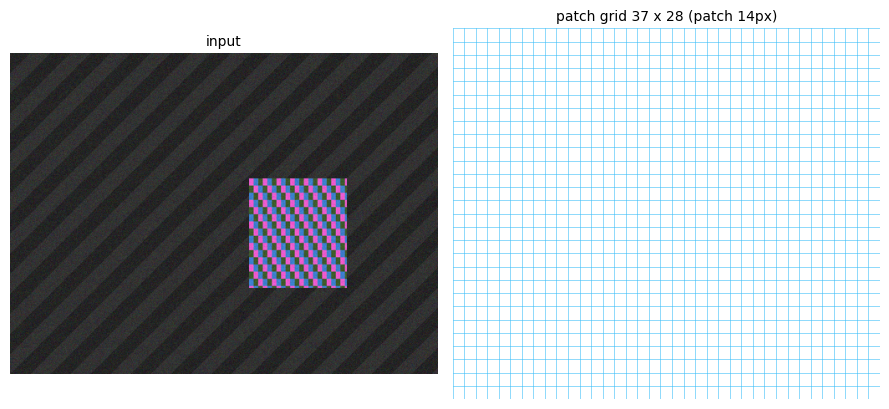

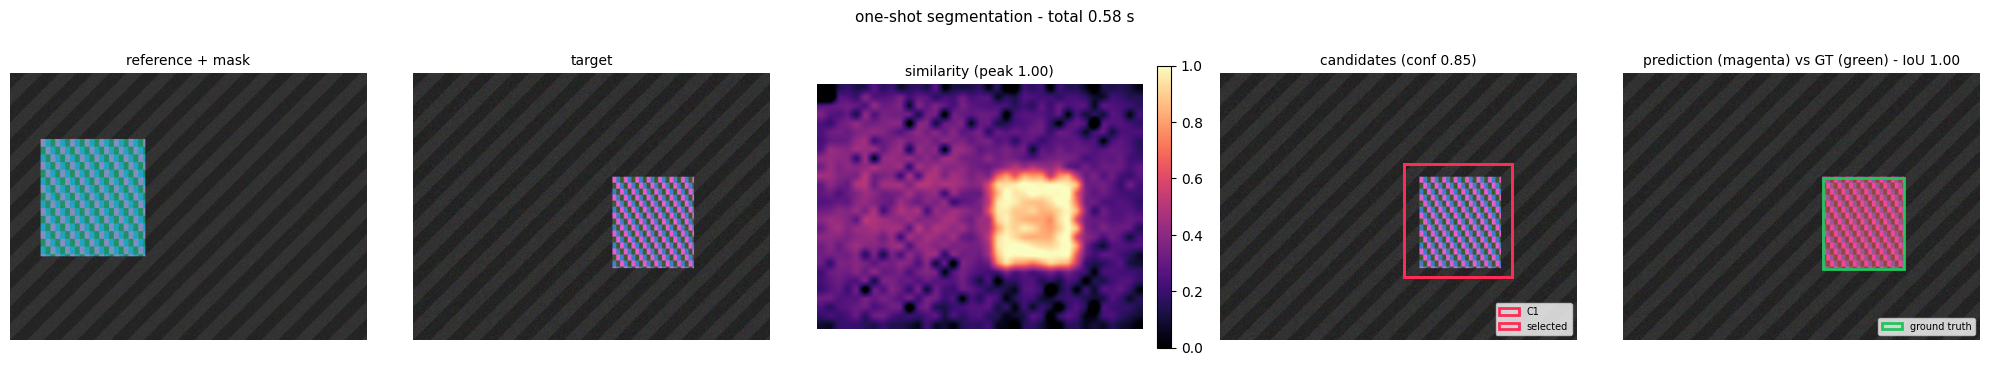

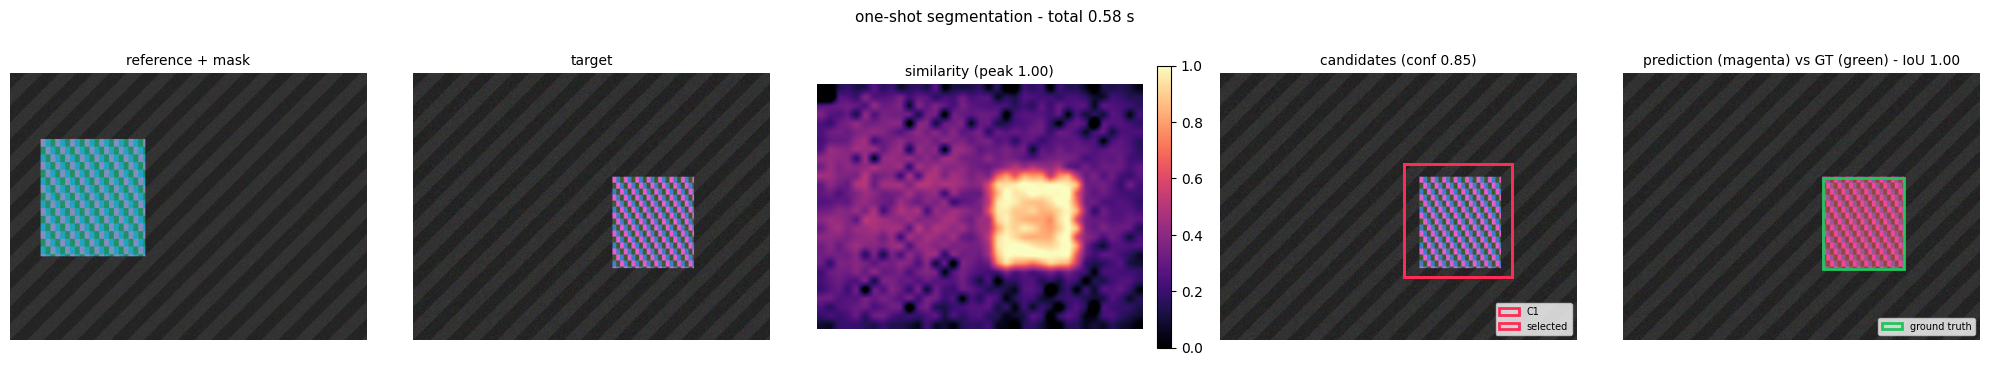

In [67]:
from visualization.results import plot_feature_grid, plot_one_shot_result

plot_feature_grid(target_features, target_image)
plot_one_shot_result(reference_image, reference_mask, target_image, result, ground_truth=target_mask)

## 11. Evaluate

IoU, Dice, precision and recall against a ground-truth mask. Phase 1 scores a
handful of manually verified examples, not a benchmark. Once a dataset is
downloaded, a `data/cases.json` manifest points the same code at COCO-20i,
FSS-1000, LVIS-92i, PACO-Part or Pascal-Part cases without touching the pipeline.

In [68]:
from evaluation.cases import cases_from_manifest, run_cases
from evaluation.metrics import evaluate_mask, evaluate_results

truth = target_mask
if truth is not None:
    print(evaluate_mask(result.predicted_mask, truth))

MANIFEST = "data/cases.json"
if os.path.exists(MANIFEST):
    cases = cases_from_manifest(MANIFEST)
    print(f"{len(cases)} cases from {MANIFEST}")
    report = run_cases(pipeline, cases)
    print(report.to_table())
    print("mean:", {key: round(value, 4) for key, value in report.summary().items()})
elif truth is not None:
    print(evaluate_results([("notebook example", result.predicted_mask, truth, result)]).to_table())
else:
    print("no ground-truth mask: upload one, keep the demo pair, or point MANIFEST at a dataset")

IoU 0.996 | Dice 0.998 | P 1.000 | R 0.996
example                      IoU    Dice       P       R    conf     sec
------------------------------------------------------------------------
notebook example           0.996   0.998   1.000   0.996   0.853    0.58
------------------------------------------------------------------------
mean                       0.996   0.998   1.000   0.996


## 12. Save result

In [69]:
OUTPUT_DIR = "results"
paths = result.save(OUTPUT_DIR, stem="one_shot_result")
print("saved:", paths)

figure_path = os.path.join(OUTPUT_DIR, "one_shot_result.png")
from visualization.results import save_result_figure

save_result_figure(figure_path, reference_image, reference_mask, target_image, result, ground_truth=truth)
print("figure:", os.path.abspath(figure_path))

saved: {'mask': 'results/one_shot_result_mask.png', 'similarity_map': 'results/one_shot_result_similarity.npy', 'summary': 'results/one_shot_result_summary.json'}
figure: /content/results/one_shot_result.png


## Reading the output honestly

* `confidence` is the mean similarity inside the selected region, not a
  calibrated probability - compare it across runs, do not threshold it as one.
* A single strong box and point can still land on a neighbour when two instances
  look alike; the candidate list exists so that case is visible instead of
  hidden.
* Everything above is frozen-feature inference. No threshold has been tuned on
  the evaluation set, and no result here should be read as a benchmark.